<a href="https://colab.research.google.com/github/sawarindev2005/Halal-Stocks/blob/main/songkhla_zoo_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# วิเคราะห์รีวิวสวนสัตว์สงขลา ทีละกราฟ

ฉบับภาษาไทยสำหรับอธิบายอาจารย์ **หนึ่งเซลล์กราฟแสดงหนึ่งภาพ** ไม่มีกราฟหลายช่องในภาพเดียว

1. เปิดใน Google Colab แล้วเลือก **Runtime → Run all** เพื่อทดสอบทั้งหมด อัปโหลด `250comment.xlsx` เมื่อมีช่องเลือกไฟล์
2. ตอนนำเสนอ สามารถกดรันทีละเซลล์ด้วย **Shift + Enter** โดยรันส่วนเตรียมข้อมูลและโมเดลให้ครบก่อนเริ่มส่วนกราฟ
3. อ่าน **คำถามของกราฟ → วิธีอ่าน → ตัวอย่างการอธิบาย** ที่อยู่กับแต่ละภาพ ตัวเลขสรุปใต้ภาพคำนวณจากไฟล์ที่อัปโหลด
4. กราฟหลัก 12 ภาพแยกตามคำถามและโมเดล ตามด้วยกราฟรายประเด็น 23 ภาพของไฟล์เดิม เลือกนำเสนอเฉพาะประเด็นที่เกี่ยวข้องได้
5. เมื่อรันจบ ดาวน์โหลด ZIP รวมกราฟ PNG ตาราง CSV และคู่มือได้จากเซลล์สุดท้าย

กราฟและคำอธิบายใช้ภาษาไทย พร้อมฟอนต์ Sarabun ที่ฝังไว้ในไฟล์ ชื่อแพลตฟอร์มยังคงใช้ Google Maps และ TripAdvisor เพื่อระบุแหล่งข้อมูล

**ขอบเขตการแปลผล:** ใช้ป้ายความรู้สึกเบื้องต้นจาก Excel ต้องตรวจว่าผู้ให้ป้ายอ่านข้อความโดยไม่ดูดาวก่อนใช้เป็นข้อสรุปวิจัย ประเด็นมาจากแท็กเดิม ไม่ใช่โมเดลสกัดประเด็น และคะแนนความรู้สึกเป็นระดับรีวิวทั้งข้อความ


## ตรวจแพ็กเกจ
เซลล์นี้ติดตั้งเฉพาะแพ็กเกจที่ยังไม่มีใน Colab การรันทดลองที่แนบมาบันทึกเวอร์ชันจริงไว้ใน `run_metadata.json` ผลอาจต่างเล็กน้อยเมื่อเวอร์ชันเปลี่ยน

In [ ]:
import importlib.util
import subprocess
import sys
requirements = {"pandas": "pandas", "numpy": "numpy", "openpyxl": "openpyxl",
                "sklearn": "scikit-learn", "scipy": "scipy", "matplotlib": "matplotlib"}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("แพ็กเกจพร้อมใช้งาน")


แพ็กเกจพร้อมใช้งาน


## 1 เตรียมเครื่องมือ

แก้ค่าตั้งต้นได้ที่นี่ ครั้งแรกปล่อย INPUT_FILE และ ANNOTATION_FILE ว่างไว้ หากมีป้ายที่คนตรวจอย่างอิสระแล้ว ให้อัปโหลด CSV ทางแถบ Files ก่อนรัน และใส่ path ใน ANNOTATION_FILE การเปลี่ยน flag อย่างเดียวไม่ได้ทำให้ป้ายผ่านการตรวจ

In [ ]:
"""วิเคราะห์ 250comment.xlsx ตาม proposal สวนสัตว์สงขลา
ใช้ใน Colab: วางโค้ดทั้งหมดในเซลล์แล้วรัน หรือเปิด notebook ที่ให้มาคู่กัน
บนเครื่อง: python songkhla_zoo_analysis.py /path/250comment.xlsx
ต้องมี pandas numpy openpyxl scikit-learn scipy matplotlib
"""
import sys
import re
import json
import hashlib
import unicodedata
import importlib.metadata
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

SEED = 42
INPUT_FILE = ""  # ว่างไว้เพื่ออัปโหลด Excel ใน Colab
ANNOTATION_FILE = ""  # ใส่ path CSV ที่ตรวจป้ายจากข้อความแล้ว ถ้ามี
SHOW_PLOTS = True
# ข้อมูลเดิมมีป้ายเบื้องต้นเท่านั้น ค่าด้านล่างใช้สำหรับแสดงสถานะ ไม่แก้ผลคำนวณ
LABELS_INDEPENDENTLY_VERIFIED = False

plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.labelsize": 10})
COLORS = {"negative": "#c75a45", "neutral": "#9a9eaa", "positive": "#328a80"}
CLASSES = np.array(["negative", "neutral", "positive"])
LABEL_MAP = {"เชิงลบ": "negative", "ลบ": "negative", "negative": "negative",
             "เป็นกลาง": "neutral", "เชิงกลาง": "neutral", "กลาง": "neutral", "neutral": "neutral",
             "เชิงบวก": "positive", "บวก": "positive", "positive": "positive"}
TOPIC_EN = {"สัตว์": "Animals", "จำนวนสัตว์": "Animal numbers", "การแสดง": "Shows",
 "กิจกรรม": "Activities", "ครอบครัว": "Family", "ความประทับใจ": "Overall impressions",
 "ความคิดเห็นทั่วไป": "General comments", "บรรยากาศ": "Atmosphere", "วิว": "Views",
 "การบริการ": "Service", "การเดินทาง": "Transport", "ราคา": "Price", "สวนน้ำ": "Water park",
 "สวัสดิภาพสัตว์": "Animal welfare", "สิ่งอำนวยความสะดวก": "Facilities",
 "ความสะอาด": "Cleanliness", "อาหาร": "Food", "ที่จอดรถ": "Parking", "ที่พัก": "Accommodation",
 "ห้องน้ำ": "Toilets", "ความปลอดภัย": "Safety", "ความรู้": "Learning", "การปรับปรุง": "Renovation"}



## เตรียมฟอนต์และข้อความภาษาไทย

รันครั้งเดียวก่อนสร้างกราฟ ฟอนต์ถูกเก็บไว้ใน Notebook แล้ว ไม่ต้องดาวน์โหลดฟอนต์จากภายนอกตอนรัน

In [ ]:
import base64
import hashlib
import tempfile
from matplotlib import font_manager
FONT_BASE64 = '...'
FONT_SHA256 = '226d4f368fbc0457990ddef2692679badfd2c1a4e89e5ac4d43c10ba7743b2f1'
FONT_LICENSE = 'Copyright 2018 The Sarabun Project Authors (https://github.com/cadsondemak/Sarabun)\n\nThis Font Software is licensed under the SIL Open Font License, Version 1.1.\nThis license is copied below, and is also available with a FAQ at:\nhttp://scripts.sil.org/OFL\n\n\n-----------------------------------------------------------\nSIL OPEN FONT LICENSE Version 1.1 - 26 February 2007\n-----------------------------------------------------------\n\nPREAMBLE\nThe goals of the Open Font License (OFL) are to stimulate worldwide\ndevelopment of collaborative font projects, to support the font creation\nefforts of academic and linguistic communities, and to provide a free and\nopen framework in which fonts may be shared and improved in partnership\nwith others.\n\nThe OFL allows the licensed fonts to be used, studied, modified and\nredistributed freely as long as they are not sold by themselves. The\nfonts, including any derivative works, can be bundled, embedded, \nredistributed and/or sold with any software provided that any reserved\nnames are not used by derivative works. The fonts and derivatives,\nhowever, cannot be released under any other type of license. The\nrequirement for fonts to remain under this license does not apply\nto any document created using the fonts or their derivatives.\n\nDEFINITIONS\n"Font Software" refers to the set of files released by the Copyright\nHolder(s) under this license and clearly marked as such. This may\ninclude source files, build scripts and documentation.\n\n"Reserved Font Name" refers to any names specified as such after the\ncopyright statement(s).\n\n"Original Version" refers to the collection of Font Software components as\ndistributed by the Copyright Holder(s).\n\n"Modified Version" refers to any derivative made by adding to, deleting,\nor substituting -- in part or in whole -- any of the components of the\nOriginal Version, by changing formats or by porting the Font Software to a\nnew environment.\n\n"Author" refers to any designer, engineer, programmer, technical\nwriter or other person who contributed to the Font Software.\n\nPERMISSION & CONDITIONS\nPermission is hereby granted, free of charge, to any person obtaining\na copy of the Font Software, to use, study, copy, merge, embed, modify,\nredistribute, and sell modified and unmodified copies of the Font\nSoftware, subject to the following conditions:\n\n1) Neither the Font Software nor any of its individual components,\nin Original or Modified Versions, may be sold by itself.\n\n2) Original or Modified Versions of the Font Software may be bundled,\nredistributed and/or sold with any software, provided that each copy\ncontains the above copyright notice and this license. These can be\nincluded either as stand-alone text files, human-readable headers or\nin the appropriate machine-readable metadata fields within text or\nbinary files as long as those fields can be easily viewed by the user.\n\n3) No Modified Version of the Font Software may use the Reserved Font\nName(s) unless explicit written permission is granted by the corresponding\nCopyright Holder. This restriction only applies to the primary font name as\npresented to the users.\n\n4) The name(s) of the Copyright Holder(s) or the Author(s) of the Font\nSoftware shall not be used to promote, endorse or advertise any\nModified Version, except to acknowledge the contribution(s) of the\nCopyright Holder(s) and the Author(s) or with their explicit written\npermission.\n\n5) The Font Software, modified or unmodified, in part or in whole,\nmust be distributed entirely under this license, and must not be\ndistributed under any other license. The requirement for fonts to\nremain under this license does not apply to any document created\nusing the Font Software.\n\nTERMINATION\nThis license becomes null and void if any of the above conditions are\nnot met.\n\nDISCLAIMER\nTHE FONT SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND,\nEXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO ANY WARRANTIES OF\nMERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT\nOF COPYRIGHT, PATENT, TRADEMARK, OR OTHER RIGHT. IN NO EVENT SHALL THE\nCOPYRIGHT HOLDER BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY,\nINCLUDING ANY GENERAL, SPECIAL, INDIRECT, INCIDENTAL, OR CONSEQUENTIAL\nDAMAGES, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING\nFROM, OUT OF THE USE OR INABILITY TO USE THE FONT SOFTWARE OR FROM\nOTHER DEALINGS IN THE FONT SOFTWARE.\n'
font_dir = Path(tempfile.gettempdir()) / "songkhla_zoo_thai_font"
font_dir.mkdir(exist_ok=True)
font_bytes = base64.b64decode(FONT_BASE64)
assert hashlib.sha256(font_bytes).hexdigest() == FONT_SHA256
font_path = font_dir / "Sarabun-Regular.ttf"
font_path.write_bytes(font_bytes)
(font_dir / "OFL.txt").write_text(FONT_LICENSE, encoding="utf-8")
font_manager.fontManager.addfont(str(font_path))
plt.rcParams.update({"font.family": font_manager.FontProperties(fname=str(font_path)).get_name(),
                     "font.size": 13, "axes.titlesize": 18, "axes.labelsize": 14,
                     "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "axes.unicode_minus": False, "figure.dpi": 110})
SENTIMENT_TH = {"negative": "เชิงลบ", "neutral": "เป็นกลาง", "positive": "เชิงบวก"}
MODEL_TH = {"Naive Bayes": "นาอีฟเบย์", "Logistic Regression": "โลจิสติกรีเกรสชัน",
            "Majority baseline": "ทายกลุ่มที่พบบ่อยเสมอ"}
print("ฟอนต์ไทยพร้อมใช้งาน")


ฟอนต์ไทยพร้อมใช้งาน


## 2 อ่านไฟล์และตรวจข้อมูล

อ่านชื่อคอลัมน์จริง ตัดช่องว่างท้ายชื่อ แก้รหัสอักขระแฝง และแปลงปี พ.ศ. เฉพาะวันที่ โค้ดคงข้อความต้นฉบับไว้ ข้อความซ้ำคงอยู่แต่ต้องไม่กระจายข้ามชุดฝึก/ทดสอบ

In [ ]:
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not INPUT_FILE:
    if IN_COLAB:
        print("เลือกไฟล์ Excel เช่น 250comment.xlsx")
        uploaded = colab_files.upload()
        candidates = [p for p in uploaded if p.lower().endswith(".xlsx")]
        if len(candidates) != 1:
            raise ValueError("กรุณาอัปโหลดไฟล์ .xlsx เพียงหนึ่งไฟล์ต่อครั้ง")
        INPUT_FILE = candidates[0]
    else:
        INPUT_FILE = next((p for p in sys.argv[1:] if p.lower().endswith('.xlsx')), "250comment.xlsx")
if not Path(INPUT_FILE).is_file():
    raise FileNotFoundError(f"ไม่พบ {INPUT_FILE} ให้แก้ INPUT_FILE หรืออัปโหลดไฟล์ใน Colab")

OUT = Path("zoo_results") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUT.mkdir(parents=True, exist_ok=True)

def save_table(frame, name, index=False):
    frame.to_csv(OUT / f"{name}.csv", index=index, encoding="utf-8-sig")

def save_plot(name):
    plt.tight_layout()
    import io
    image_buffer = io.BytesIO()
    plt.gcf().savefig(image_buffer, format="png", dpi=180, bbox_inches="tight")
    (OUT / f"{name}.png").write_bytes(image_buffer.getvalue())
    if SHOW_PLOTS:
        plt.show()
    plt.close()

def show_table(frame):
    if IN_COLAB:
        from IPython.display import display
        display(frame)
    else:
        print(frame.to_string(index=False))

def clean_text(value):
    if pd.isna(value):
        return ""
    s = unicodedata.normalize("NFC", str(value))
    # ล้างทั้ง zero-width จริงและรหัสที่ถูกเก็บเป็นข้อความใน Excel
    for token in ["\\u200b", "\\u200B", "\u200b", "\ufeff"]:
        s = s.replace(token, "")
    s = s.replace("\\n", " ").replace("\\r", " ").replace("\\t", " ")
    s = re.sub(r"https?://\S+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

raw = pd.read_excel(INPUT_FILE, sheet_name=0)
raw.columns = raw.columns.astype(str).str.strip()
if raw.columns.duplicated().any():
    raise ValueError("ชื่อคอลัมน์ซ้ำหลังตัดช่องว่าง โปรดตรวจ Excel")
rename = {"ลำดับที่": "row_id", "แพลตฟอร์ม": "platform", "คะแนนดาว (1-5)": "stars",
          "ข้อความคอมเมนต์": "text", "ประเด็นที่ถูกกล่าวถึง": "topics_raw",
          "ผลประเมินความรู้สึกเบื้องต้น": "label_raw", "วันที่โพสต์": "date_raw"}
missing = set(rename) - set(raw.columns)
if missing:
    raise ValueError(f"ไม่พบคอลัมน์ที่จำเป็น: {sorted(missing)}")
df = raw.rename(columns=rename).copy()
if df['row_id'].isna().any() or df['row_id'].duplicated().any():
    raise ValueError("ลำดับที่ต้องไม่ว่างและไม่ซ้ำ เพื่อเชื่อมป้ายและผลทำนายได้ถูกต้อง")
df["text_clean"] = df["text"].map(clean_text)
df["stars"] = pd.to_numeric(df["stars"], errors="coerce")
valid = df["stars"].isin([1, 2, 3, 4, 5]) & df["text_clean"].str.contains(r"[ก-๙]", regex=True)
save_table(df.loc[~valid, ["row_id", "stars", "text"]], "excluded_rows")
df = df.loc[valid].reset_index(drop=True)
if df.empty:
    raise ValueError("ไม่มีรีวิวภาษาไทยพร้อมคะแนน 1–5 ที่ใช้วิเคราะห์ได้")
df["platform"] = df["platform"].fillna("Unknown").astype(str).str.strip()
df["label"] = df["label_raw"].astype(str).str.strip().str.lower().map(LABEL_MAP)
df["text_group"] = df["text_clean"].str.lower().str.replace(r"\s+", "", regex=True)
df["topics"] = df["topics_raw"].fillna("").astype(str).map(
    lambda s: sorted({t.strip() for t in re.split(r"[,，;]", s) if t.strip()}))
df["text_hash"] = df["text_clean"].map(lambda s: hashlib.sha256(s.encode()).hexdigest())

def parse_date(value):
    try:
        if isinstance(value, (datetime, pd.Timestamp)):
            y, m, d = value.year, value.month, value.day
        else:
            a = re.fullmatch(r"\s*(\d{1,2})/(\d{1,2})/(\d{4})\s*", str(value))
            if not a:
                return pd.NaT
            d, m, y = map(int, a.groups())
        return pd.Timestamp(datetime(y - 543 if y >= 2400 else y, m, d))
    except (ValueError, OverflowError):
        return pd.NaT

df["date_ce"] = df["date_raw"].map(parse_date)
audit = {"input_rows": len(raw), "valid_review_rows": len(df), "excluded_rows": int((~valid).sum()),
         "repeated_normalized_text_rows": int(df['text_group'].duplicated().sum()),
         "missing_labels": int(df['label'].isna().sum()), "unparsed_dates": int(df['date_ce'].isna().sum())}
print("สรุปข้อมูล:", audit)
print("วันที่ใช้เพื่อบอกช่วงข้อมูลเท่านั้น ไม่ได้นำเข้าโมเดล")
print("ข้อความซ้ำคงไว้เพราะอาจเป็นคนละรีวิว แต่จัดให้อยู่ fold เดียวกันเสมอ")
save_table(df.loc[df.text_group.duplicated(False), ['row_id', 'platform', 'text', 'stars', 'label']], 'duplicate_texts')
blind = df[['row_id', 'text', 'text_hash']].sample(frac=1, random_state=SEED).copy()
blind['sentiment_verified'] = ''
blind['annotator_1'] = ''
blind['annotator_2'] = ''
save_table(blind, 'blind_annotation_template')



สรุปข้อมูล: {'input_rows': 300, 'valid_review_rows': 300, 'excluded_rows': 0, 'repeated_normalized_text_rows': 1, 'missing_labels': 0, 'unparsed_dates': 0}
วันที่ใช้เพื่อบอกช่วงข้อมูลเท่านั้น ไม่ได้นำเข้าโมเดล
ข้อความซ้ำคงไว้เพราะอาจเป็นคนละรีวิว แต่จัดให้อยู่ fold เดียวกันเสมอ


## 3 ตรวจป้ายความรู้สึกและเตรียมชุดฝึก

ป้าย y เป็นค่าที่ประเมินจากข้อความ ควรใช้ป้ายที่ตรวจโดยไม่เห็นดาว การจัดดาว 1–2/3/4–5 ในเซลล์นี้ใช้ตรวจความตรงกันและหารายการให้คนตรวจเท่านั้น ไม่ใช้ฝึกโมเดล

In [ ]:
if ANNOTATION_FILE:
    ann = pd.read_csv(ANNOTATION_FILE, encoding='utf-8-sig')
    needed = {'row_id', 'text_hash', 'sentiment_verified'}
    if not needed.issubset(ann.columns) or ann.row_id.duplicated().any():
        raise ValueError('CSV ต้องมี row_id ไม่ซ้ำ text_hash และ sentiment_verified')
    ann = ann[list(needed)].copy()
    joined = df[['row_id', 'text_hash']].merge(ann, on='row_id', how='left', suffixes=('_source', '_annotation'), validate='one_to_one')
    if ((joined.text_hash_annotation.notna()) & (joined.text_hash_source != joined.text_hash_annotation)).any():
        raise ValueError('ข้อความเปลี่ยนไปจากตอนทำป้าย กรุณาตรวจ text_hash และให้ป้ายใหม่')
    df['label'] = joined.sentiment_verified.astype(str).str.strip().str.lower().map(LABEL_MAP)
    label_source = 'independent annotation CSV (user supplied)'
else:
    label_source = 'preliminary labels from Excel'
    print('ผลนี้เป็นการทดลองจากป้ายเบื้องต้น ต้องตรวจที่มาของป้ายก่อนใช้เป็นข้อสรุปวิจัย')

data = df.dropna(subset=['label']).reset_index(drop=True)
if set(data.label.unique()) != set(CLASSES):
    raise ValueError('ต้องมีป้ายเชิงลบ เป็นกลาง และเชิงบวกครบทั้ง 3 กลุ่ม ห้ามสร้างป้ายจากดาวเพื่อเติมข้อมูล')
star_band = np.where(data.stars <= 2, 'negative', np.where(data.stars == 3, 'neutral', 'positive'))
agreement = float(np.mean(star_band == data.label.to_numpy()))
audit.update({'model_rows': len(data), 'label_star_band_agreement': agreement, 'label_source': label_source})
print(f'ป้ายตรงกับกลุ่มดาว 1–2/3/4–5: {(star_band == data.label).sum()}/{len(data)} ({agreement:.1%})')
print('ค่านี้เป็นการตรวจป้าย ไม่ใช่ accuracy ของโมเดล และไม่ได้ยืนยันว่าป้ายถูกสร้างจากดาว')
if agreement >= .95:
    print('ควรให้ผู้ประเมินอ่านเฉพาะข้อความโดยไม่เห็นดาว แล้วตกลงป้ายที่เห็นต่างก่อนทดลองจริง')
label_cross = pd.crosstab(data.stars, data.label).reindex(index=range(1,6), columns=CLASSES, fill_value=0)
save_table(label_cross, 'star_vs_input_label', index=True)
show_table(label_cross.reset_index())



ผลนี้เป็นการทดลองจากป้ายเบื้องต้น ต้องตรวจที่มาของป้ายก่อนใช้เป็นข้อสรุปวิจัย
ป้ายตรงกับกลุ่มดาว 1–2/3/4–5: 295/300 (98.3%)
ค่านี้เป็นการตรวจป้าย ไม่ใช่ accuracy ของโมเดล และไม่ได้ยืนยันว่าป้ายถูกสร้างจากดาว
ควรให้ผู้ประเมินอ่านเฉพาะข้อความโดยไม่เห็นดาว แล้วตกลงป้ายที่เห็นต่างก่อนทดลองจริง
 stars  negative  neutral  positive
     1        14        1         0
     2        10        0         0
     3         2       25         1
     4         0        1        96
     5         0        0       150


## 4 ฝึกและทำนายแบบ out of fold

TF-IDF แปลงชิ้นตัวอักษร 3–5 ตัวเป็นตัวเลข จากนั้นฝึกทั้งสองโมเดล ใช้ 5-fold แบบรักษากลุ่มข้อความซ้ำ และสร้าง out-of-fold predictions สำหรับทุกแถว ทั้ง TF-IDF และโมเดลเรียนรู้เฉพาะชุดฝึก ไม่ได้ใช้ PyThaiNLP ในเวอร์ชันนี้

In [ ]:
# โมเดลใช้ข้อความเท่านั้น ไม่ใช้ดาว แพลตฟอร์ม ประเด็น หรือข้อมูลผู้รีวิวเป็น feature
# Character n-grams 3–5 ตัวอักษรเหมาะเป็น baseline ที่ไม่ต้องตัดคำไทย
# เช่น สนุกมาก -> สนุ, นุก, ุกม, ... ไม่ใช่รายการคำศัพท์
# เก็บคำปฏิเสธและ emoji ไม่ลบ stopwords แบบเหมา
group_counts = data.groupby('label')['text_group'].nunique()
n_splits = min(5, int(group_counts.min()))
if n_splits < 2:
    raise ValueError('ข้อมูลแต่ละคลาสต้องมีอย่างน้อย 2 กลุ่มข้อความที่ไม่ซ้ำกัน')
cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
splits = list(cv.split(data.text_clean, data.label, groups=data.text_group))
model_names = ['Naive Bayes', 'Logistic Regression', 'Majority baseline']
probs = {name: np.full((len(data), 3), np.nan) for name in model_names}
fold_id = np.full(len(data), -1)
fold_scores = []

def build_model(name):
    if name == 'Naive Bayes':
        classifier = MultinomialNB(alpha=1.0)
    elif name == 'Logistic Regression':
        classifier = LogisticRegression(C=1.0, max_iter=3000, class_weight='balanced', random_state=SEED)
    else:
        classifier = DummyClassifier(strategy='most_frequent')
    return Pipeline([('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(3,5),
                                            min_df=1, max_features=30000, sublinear_tf=True)),
                     ('clf', classifier)])

for fold, (train_idx, test_idx) in enumerate(splits, 1):
    train, test = data.iloc[train_idx], data.iloc[test_idx]
    assert not set(train.text_group) & set(test.text_group), 'ข้อความซ้ำหลุดข้ามชุดฝึกและทดสอบ'
    if set(train.label.unique()) != set(CLASSES):
        raise ValueError('fold มีคลาสฝึกไม่ครบ โปรดเพิ่มตัวอย่างหรือปรับจำนวน fold')
    fold_id[test_idx] = fold
    for name in model_names:
        model = build_model(name)
        fit_args = {}
        if name == 'Naive Bayes':
            fit_args['clf__sample_weight'] = compute_sample_weight('balanced', train.label)
        model.fit(train.text_clean, train.label, **fit_args)
        p = model.predict_proba(test.text_clean)
        # จัดคอลัมน์ probability ตามชื่อคลาส ไม่สมมติลำดับคอลัมน์
        order = [list(model.named_steps['clf'].classes_).index(c) for c in CLASSES]
        probs[name][test_idx] = p[:, order]
        pred = CLASSES[np.argmax(p[:, order], axis=1)]
        fold_scores.append({'model': name, 'fold': fold, 'n_train': len(train), 'n_test': len(test),
                            'macro_f1': f1_score(test.label, pred, labels=CLASSES, average='macro', zero_division=0)})
    print(f'เสร็จ fold {fold}/{n_splits}')



เสร็จ fold 1/5
เสร็จ fold 2/5
เสร็จ fold 3/5
เสร็จ fold 4/5
เสร็จ fold 5/5


## 5 เปรียบเทียบประสิทธิภาพ

Accuracy คือสัดส่วนทายถูกทั้งหมด ส่วน Macro-F1 เฉลี่ย F1 ของทั้งสามคลาสเท่ากัน เหมาะช่วยตรวจว่ากลุ่มลบ/กลางถูกละเลยหรือไม่ Majority baseline ทายคลาสที่พบบ่อยในชุดฝึกเสมอ ข้อมูลตัวอย่างนี้ Accuracy baseline สูงถึงประมาณ 82%

In [ ]:
data['fold'] = fold_id
metrics = []
for name, p in probs.items():
    assert np.isfinite(p).all() and np.allclose(p.sum(axis=1), 1)
    pred = CLASSES[p.argmax(axis=1)]
    data[f'{name}_prediction'] = pred
    # นิยามคะแนนความรู้สึกเชิงต่อเนื่อง s = P(positive) - P(negative) อยู่ในช่วง -1 ถึง 1
    # เป็นคะแนนจากโมเดล ไม่ใช่ความน่าจะเป็นที่ปรับเทียบแล้วหรือระดับความพึงพอใจจริง
    data[f'{name}_score'] = p[:, 2] - p[:, 0]
    for j, c in enumerate(CLASSES):
        data[f'{name}_p_{c}'] = p[:,j]
    metrics.append({'model': name, 'accuracy': accuracy_score(data.label, pred),
                    'macro_f1': f1_score(data.label, pred, labels=CLASSES, average='macro', zero_division=0),
                    'balanced_accuracy': balanced_accuracy_score(data.label, pred)})
    report = pd.DataFrame(classification_report(data.label, pred, labels=CLASSES,
                         output_dict=True, zero_division=0)).T
    save_table(report, f'report_{name.replace(" ", "_")}', index=True)
metrics = pd.DataFrame(metrics)
save_table(metrics, 'model_comparison')
save_table(pd.DataFrame(fold_scores), 'fold_scores')
show_table(metrics)
print('อ่าน Macro-F1 และ recall รายคลาสควบคู่ Accuracy เพราะป้ายบวกมีจำนวนมาก')
print('พารามิเตอร์กำหนดล่วงหน้า ไม่ได้เลือกจากผลดาวหรือปรับจน correlation สูง')
print('ผลทั้งหมดใช้ out-of-fold จึงไม่ใช่ผลทำนายบนข้อมูลที่โมเดลตัวนั้นเคยฝึก')



              model  accuracy  macro_f1  balanced_accuracy
        Naive Bayes  0.590000  0.477212           0.598815
Logistic Regression  0.850000  0.481340           0.446894
  Majority baseline  0.823333  0.301036           0.333333
อ่าน Macro-F1 และ recall รายคลาสควบคู่ Accuracy เพราะป้ายบวกมีจำนวนมาก
พารามิเตอร์กำหนดล่วงหน้า ไม่ได้เลือกจากผลดาวหรือปรับจน correlation สูง
ผลทั้งหมดใช้ out-of-fold จึงไม่ใช่ผลทำนายบนข้อมูลที่โมเดลตัวนั้นเคยฝึก


## 6 ความสัมพันธ์คะแนนดาวกับผลความรู้สึก

คะแนนข้อความ s = P(positive) − P(negative) ค่า r ทางบวกหมายถึงดาวกับคะแนนข้อความมีแนวโน้มเพิ่มไปด้วยกัน รายงานทั้งสองโมเดล ไม่เลือกโมเดลที่ให้ r สูงเพื่อยืนยันสมมติฐาน การทำนาย OOF ช่วยลดการจำชุดฝึก แต่แก้ป้ายที่อิงดาวไม่ได้

In [ ]:
def correlations(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    if len(x) < 3 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return {'n': len(x), 'pearson_r': np.nan, 'spearman_rho': np.nan}
    return {'n': len(x), 'pearson_r': float(pearsonr(x,y).statistic),
            'spearman_rho': float(spearmanr(x,y).statistic)}

corr_rows = []
for name in model_names[:2]:
    for platform in ['All'] + sorted(data.platform.unique().tolist()):
        d = data if platform == 'All' else data[data.platform == platform]
        corr_rows.append({'model': name, 'platform': platform,
                          **correlations(d.stars, d[f'{name}_score'])})
corr_table = pd.DataFrame(corr_rows)
save_table(corr_table, 'correlations')
show_table(corr_table)
print('r > 0: ดาวสูงมักพบคะแนนข้อความเชิงบวกสูง | r < 0: ทิศทางตรงกันข้าม')
print('r ใกล้ 0: ความสัมพันธ์เชิงเส้นน้อย ไม่ได้แปลว่าไม่มีความสัมพันธ์ทุกแบบ')
print('รายงาน r และ rho เชิงพรรณนา ไม่คำนวณ p-value แบบอิสระจาก OOF ที่ใช้ชุดฝึกร่วมกัน')
print('Spearman เป็นการตรวจเพิ่มเติมเพราะดาวเป็นข้อมูลอันดับ ความสัมพันธ์ไม่พิสูจน์เหตุและผล')



              model    platform   n  pearson_r  spearman_rho
        Naive Bayes         All 300   0.559237      0.425603
        Naive Bayes Google Maps 253   0.597506      0.471050
        Naive Bayes TripAdvisor  47   0.354207      0.312237
Logistic Regression         All 300   0.609412      0.485027
Logistic Regression Google Maps 253   0.639377      0.512867
Logistic Regression TripAdvisor  47   0.401016      0.361128
r > 0: ดาวสูงมักพบคะแนนข้อความเชิงบวกสูง | r < 0: ทิศทางตรงกันข้าม
r ใกล้ 0: ความสัมพันธ์เชิงเส้นน้อย ไม่ได้แปลว่าไม่มีความสัมพันธ์ทุกแบบ
รายงาน r และ rho เชิงพรรณนา ไม่คำนวณ p-value แบบอิสระจาก OOF ที่ใช้ชุดฝึกร่วมกัน
Spearman เป็นการตรวจเพิ่มเติมเพราะดาวเป็นข้อมูลอันดับ ความสัมพันธ์ไม่พิสูจน์เหตุและผล


## 7 วิเคราะห์ประเด็นจากแท็กเดิมใน Excel

ใช้แท็กที่ผู้เก็บข้อมูลใส่ใน Excel ไม่ใช่โมเดลสกัดประเด็นใหม่ หนึ่งรีวิวมีหลายแท็กได้ ผลรวมร้อยละจึงเกิน 100 ได้ ตารางภายในแต่ละประเด็นใช้รีวิวอย่างน้อย 10 แถว และคะแนนความรู้สึกยังเป็นระดับรีวิวทั้งข้อความ

In [ ]:
# หนึ่งรีวิวพูดได้หลายประเด็น จึงนับรีวิวไม่ซ้ำภายในแต่ละประเด็น
# ไม่ได้ฝึก ML แยกประเด็น และไม่ใช่ความรู้สึกเฉพาะด้าน (aspect sentiment)
topic_long = df[['row_id','stars','topics']].explode('topics').dropna(subset=['topics'])
topic_summary = topic_long.groupby('topics').agg(n_reviews=('row_id','nunique'), mean_stars=('stars','mean')).reset_index()
topic_summary['review_percent'] = 100 * topic_summary.n_reviews / len(df)
topic_summary = topic_summary.sort_values('n_reviews', ascending=False).reset_index(drop=True)
topic_summary['plot_label'] = [TOPIC_EN.get(t, f'Topic {i+1}') for i,t in enumerate(topic_summary.topics)]
topic_labels = dict(zip(topic_summary.topics, topic_summary.plot_label))
save_table(topic_summary, 'topic_summary')
show_table(topic_summary.head(15))
topic_corr = []
for topic in topic_summary.topics:
    # การมีประเด็น (0/1) เทียบดาว คือ point-biserial ซึ่งเท่ากับ Pearson ของตัวแปรทวิภาค
    mentioned = df.topics.map(lambda tags: topic in tags).astype(int)
    topic_corr.append({'topic': topic, 'comparison': 'mention vs stars',
                       **correlations(mentioned, df.stars), 'n_mentions': int(mentioned.sum())})
    for name in model_names[:2]:
        d = data[data.topics.map(lambda tags: topic in tags)]
        if len(d) >= 10:
            topic_corr.append({'topic': topic, 'comparison': f'{name} score vs stars within topic',
                               **correlations(d.stars, d[f'{name}_score']), 'n_mentions': len(d)})
save_table(pd.DataFrame(topic_corr), 'topic_correlations')



        topics  n_reviews  mean_stars  review_percent          plot_label
         สัตว์        211    4.208531       70.333333             Animals
      ครอบครัว        117    4.333333       39.000000              Family
  ความประทับใจ         82    4.439024       27.333333 Overall impressions
       การแสดง         74    4.270270       24.666667               Shows
      บรรยากาศ         62    4.370968       20.666667          Atmosphere
    การเดินทาง         60    4.050000       20.000000           Transport
     การบริการ         48    3.750000       16.000000             Service
          ราคา         48    3.895833       16.000000               Price
    จำนวนสัตว์         45    3.711111       15.000000      Animal numbers
        สวนน้ำ         43    3.860465       14.333333          Water park
           วิว         36    4.388889       12.000000               Views
       กิจกรรม         31    4.419355       10.333333          Activities
สวัสดิภาพสัตว์         24    3.333333 

# เริ่มนำเสนอทีละกราฟ

ส่วนนี้ใช้ผลโมเดลที่คำนวณด้านบน แต่ละเซลล์สร้างเพียงภาพเดียว ป้ายกำกับบนกราฟเป็นภาษาไทย

**ข้อควรบอกอาจารย์ก่อนเริ่ม:** “ผลนี้เป็นการทดลองเบื้องต้นจากป้ายเดิมใน Excel และใช้ผลทำนายจากโมเดลที่ไม่เคยเห็นรีวิวนั้นตอนฝึก”


## ภาพที่ 1 การกระจายคะแนนดาว

**คำถาม:** ผู้รีวิวในข้อมูลชุดนี้ให้ดาวระดับใดมากที่สุด?

**วิธีอ่าน:** แกนนอนคือคะแนน 1–5 ดาว แกนตั้งคือจำนวนรีวิว ตัวเลขบนแท่งคือจำนวนจริง

**แนวทางอธิบาย:** เริ่มจากบอกจำนวนรีวิวทั้งหมด แล้วชี้ว่าดาวระดับใดมากที่สุด ข้อมูลนี้บอกคะแนนที่ผู้รีวิวให้ ยังไม่ใช่ผลวิเคราะห์ข้อความ

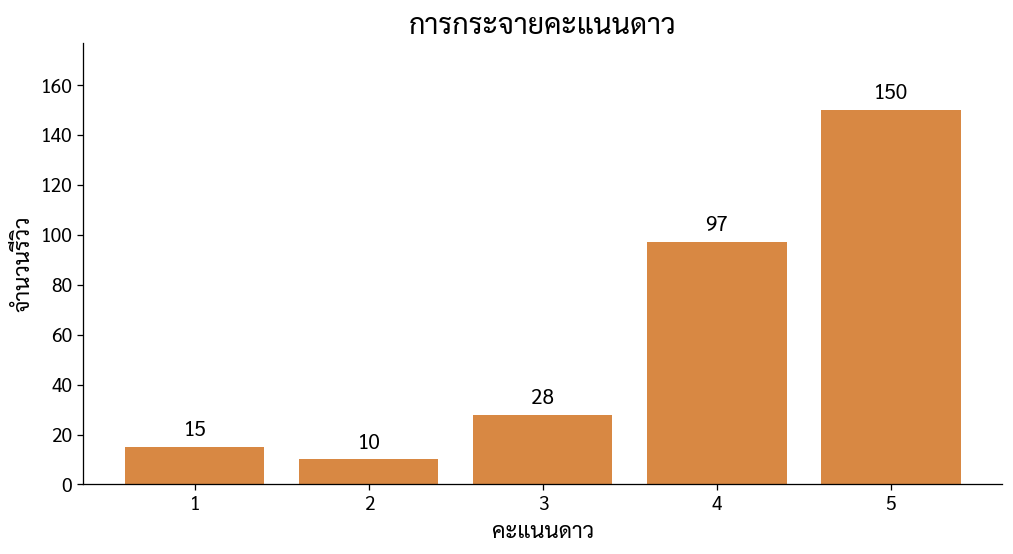

มีรีวิวทั้งหมด 300 รีวิว กลุ่มที่พบมากที่สุดคือ 5 ดาว จำนวน 150 รีวิว


In [ ]:
star_counts = df.stars.value_counts().reindex(range(1, 6), fill_value=0)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(star_counts.index, star_counts.values, color="#d88843")
ax.bar_label(bars, padding=4)
ax.set(title="การกระจายคะแนนดาว", xlabel="คะแนนดาว", ylabel="จำนวนรีวิว",
       xticks=range(1, 6), ylim=(0, star_counts.max()*1.18))
save_plot("01_star_distribution_th")
print(f"มีรีวิวทั้งหมด {len(df):,} รีวิว กลุ่มที่พบมากที่สุดคือ {star_counts.idxmax()} ดาว จำนวน {star_counts.max():,} รีวิว")


## ภาพที่ 2 แหล่งที่มาของรีวิว

**คำถาม:** ข้อมูลมาจากแพลตฟอร์มใดบ้าง?

**วิธีอ่าน:** แต่ละแท่งคือแพลตฟอร์ม ความสูงและตัวเลขคือจำนวนรีวิว

**แนวทางอธิบาย:** บอกว่าจำนวนรีวิวจากแต่ละแหล่งไม่เท่ากัน จึงควรดูผลแยกแพลตฟอร์มในตารางประกอบด้วย

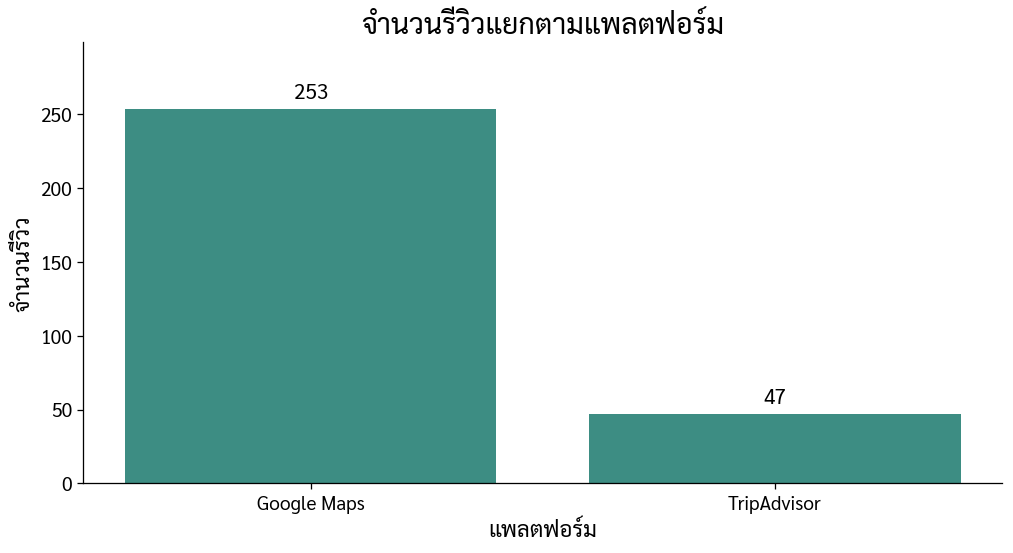

Google Maps: 253 รีวิว (84.3%)
TripAdvisor: 47 รีวิว (15.7%)


In [ ]:
platform_counts = df.platform.value_counts()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(platform_counts.index, platform_counts.values, color="#3d8d83")
ax.bar_label(bars, padding=4)
ax.set(title="จำนวนรีวิวแยกตามแพลตฟอร์ม", xlabel="แพลตฟอร์ม", ylabel="จำนวนรีวิว",
       ylim=(0, platform_counts.max()*1.18))
save_plot("02_platforms_th")
for platform, count in platform_counts.items():
    print(f"{platform}: {count:,} รีวิว ({count / len(df):.1%})")


## ภาพที่ 3 ป้ายความรู้สึกที่ใช้ฝึกโมเดล

**คำถาม:** รีวิวถูกจัดเป็นบวก กลาง และลบอย่างละเท่าไร?

**วิธีอ่าน:** สีเขียวคือเชิงบวก สีเทาคือเป็นกลาง สีส้มแดงคือเชิงลบ ความสูงคือจำนวนรีวิว

**แนวทางอธิบาย:** นี่คือป้ายจากผู้ประเมินใน Excel ไม่ใช่ผลทำนายของโมเดล ต้องตรวจวิธีให้ป้ายก่อนสรุปผล

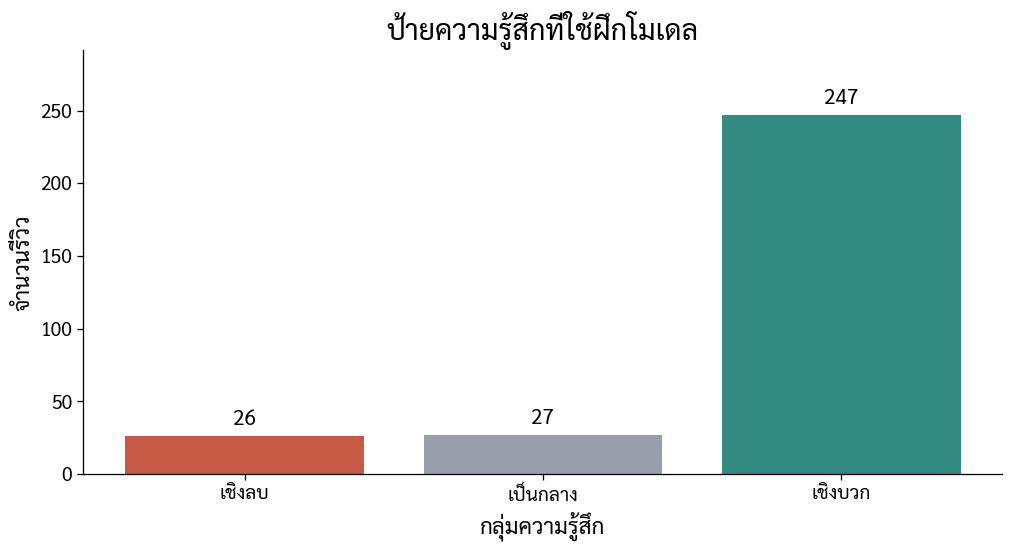

เชิงลบ: 26 รีวิว (8.7%)
เป็นกลาง: 27 รีวิว (9.0%)
เชิงบวก: 247 รีวิว (82.3%)


In [ ]:
counts = data['label'].value_counts().reindex(CLASSES, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([SENTIMENT_TH[c] for c in CLASSES], counts.values, color=[COLORS[c] for c in CLASSES])
ax.bar_label(bars, padding=4)
ax.set(title='ป้ายความรู้สึกที่ใช้ฝึกโมเดล', xlabel="กลุ่มความรู้สึก", ylabel="จำนวนรีวิว", ylim=(0, counts.max()*1.18))
save_plot("03_sentiment_th")
for cls, count in counts.items():
    print(f"{SENTIMENT_TH[cls]}: {count:,} รีวิว ({count / len(data):.1%})")


## ภาพที่ 4 ผลทำนายความรู้สึกจากนาอีฟเบย์

**คำถาม:** รีวิวถูกจัดเป็นบวก กลาง และลบอย่างละเท่าไร?

**วิธีอ่าน:** สีเขียวคือเชิงบวก สีเทาคือเป็นกลาง สีส้มแดงคือเชิงลบ ความสูงคือจำนวนรีวิว

**แนวทางอธิบาย:** นี่เป็นสัดส่วนที่โมเดลทำนาย ต้องดูความแม่นยำรายกลุ่มก่อนใช้แทนความรู้สึกจริงทั้งหมด

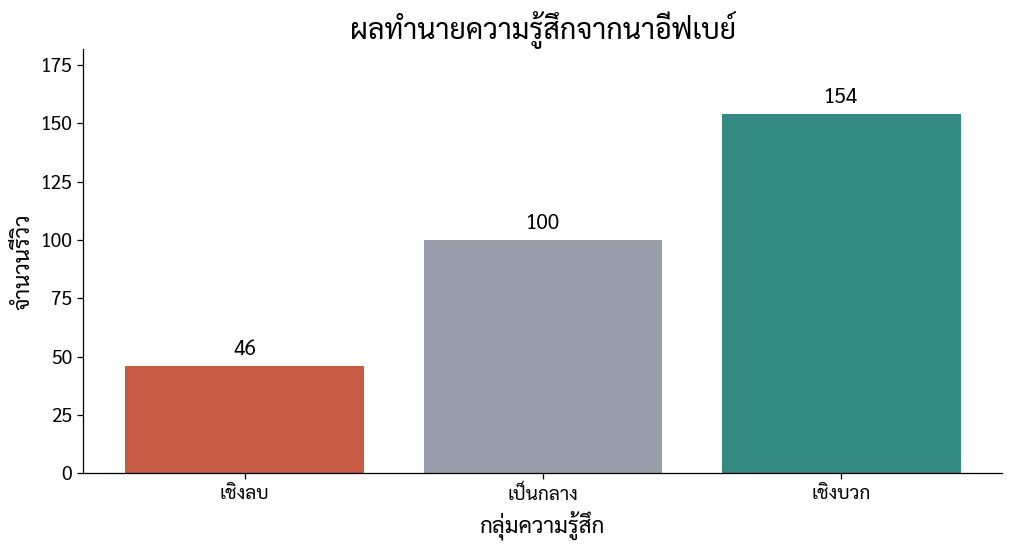

เชิงลบ: 46 รีวิว (15.3%)
เป็นกลาง: 100 รีวิว (33.3%)
เชิงบวก: 154 รีวิว (51.3%)


In [ ]:
counts = data['Naive Bayes_prediction'].value_counts().reindex(CLASSES, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([SENTIMENT_TH[c] for c in CLASSES], counts.values, color=[COLORS[c] for c in CLASSES])
ax.bar_label(bars, padding=4)
ax.set(title='ผลทำนายความรู้สึกจากนาอีฟเบย์', xlabel="กลุ่มความรู้สึก", ylabel="จำนวนรีวิว", ylim=(0, counts.max()*1.18))
save_plot("04_sentiment_th")
for cls, count in counts.items():
    print(f"{SENTIMENT_TH[cls]}: {count:,} รีวิว ({count / len(data):.1%})")


## ภาพที่ 5 ผลทำนายความรู้สึกจากโลจิสติกรีเกรสชัน

**คำถาม:** รีวิวถูกจัดเป็นบวก กลาง และลบอย่างละเท่าไร?

**วิธีอ่าน:** สีเขียวคือเชิงบวก สีเทาคือเป็นกลาง สีส้มแดงคือเชิงลบ ความสูงคือจำนวนรีวิว

**แนวทางอธิบาย:** นี่เป็นสัดส่วนที่โมเดลทำนาย ต้องดูความแม่นยำรายกลุ่มก่อนใช้แทนความรู้สึกจริงทั้งหมด

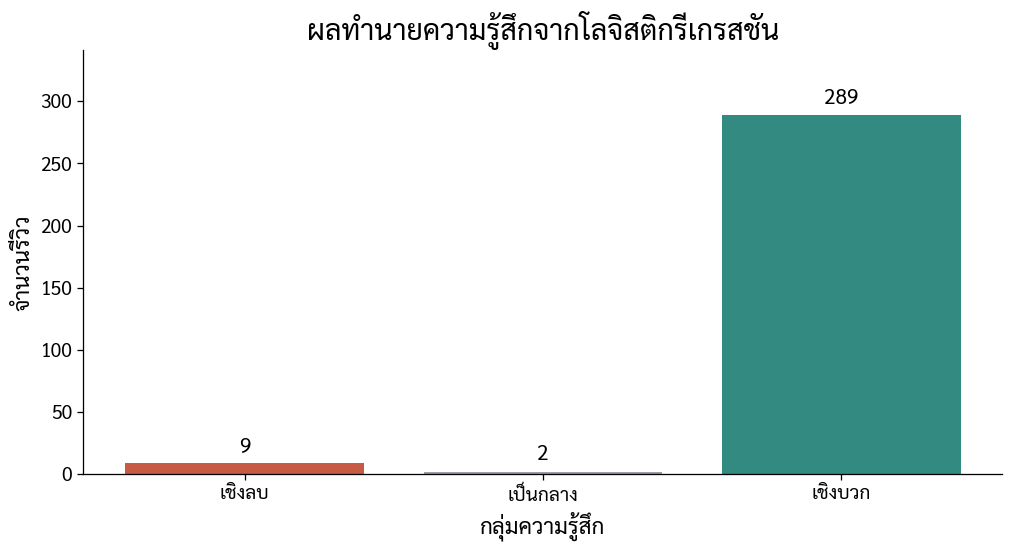

เชิงลบ: 9 รีวิว (3.0%)
เป็นกลาง: 2 รีวิว (0.7%)
เชิงบวก: 289 รีวิว (96.3%)


In [ ]:
counts = data['Logistic Regression_prediction'].value_counts().reindex(CLASSES, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([SENTIMENT_TH[c] for c in CLASSES], counts.values, color=[COLORS[c] for c in CLASSES])
ax.bar_label(bars, padding=4)
ax.set(title='ผลทำนายความรู้สึกจากโลจิสติกรีเกรสชัน', xlabel="กลุ่มความรู้สึก", ylabel="จำนวนรีวิว", ylim=(0, counts.max()*1.18))
save_plot("05_sentiment_th")
for cls, count in counts.items():
    print(f"{SENTIMENT_TH[cls]}: {count:,} รีวิว ({count / len(data):.1%})")


## ภาพที่ 6 เปรียบเทียบความสามารถของโมเดล

**คำถาม:** โมเดลจำแนกได้ดีกว่าการทายกลุ่มที่พบบ่อยเสมอหรือไม่?

**วิธีอ่าน:** แกนตั้งมีช่วง 0–1 ค่ายิ่งสูงยิ่งดี เปรียบเทียบความถูกต้องรวมกับเอฟวันเฉลี่ยทุกกลุ่ม

**แนวทางอธิบาย:** ให้ความสำคัญกับเอฟวันเฉลี่ยทุกกลุ่ม เพราะข้อมูลบวกมีมาก ความถูกต้องรวมสูงจึงอาจซ่อนปัญหาทายกลุ่มกลางหรือลบผิด

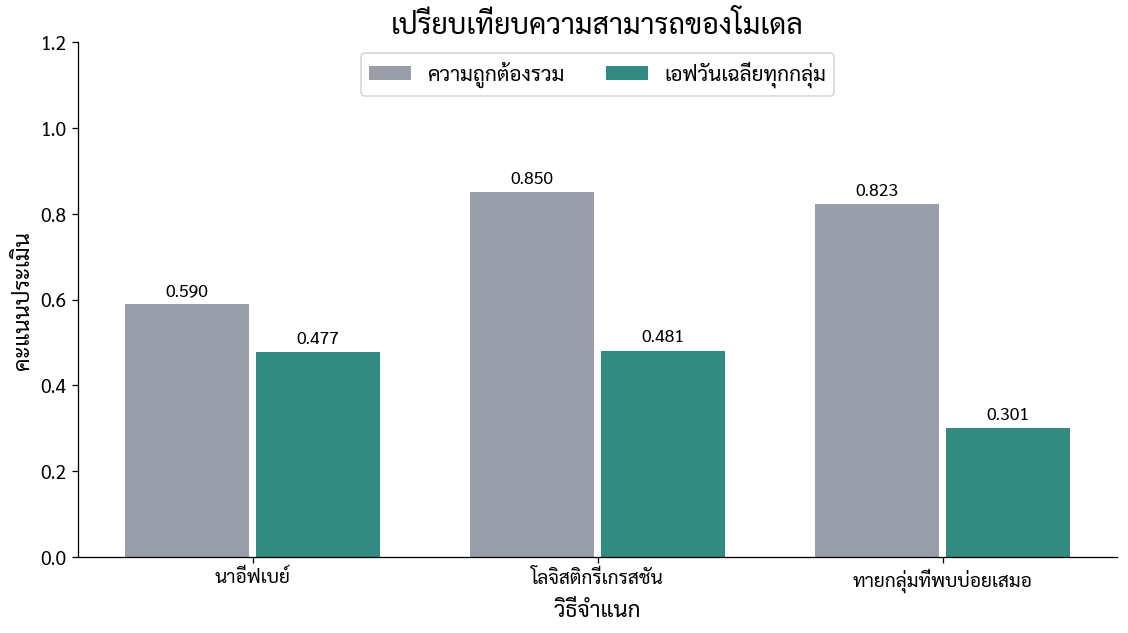

นาอีฟเบย์: ความถูกต้องรวม 59.0%, เอฟวันเฉลี่ยทุกกลุ่ม 0.477
โลจิสติกรีเกรสชัน: ความถูกต้องรวม 85.0%, เอฟวันเฉลี่ยทุกกลุ่ม 0.481
ทายกลุ่มที่พบบ่อยเสมอ: ความถูกต้องรวม 82.3%, เอฟวันเฉลี่ยทุกกลุ่ม 0.301


In [ ]:
m = metrics.set_index("model").reindex(model_names)
x = np.arange(len(m))
fig, ax = plt.subplots(figsize=(10, 5.7))
b1 = ax.bar(x - .19, m.accuracy, width=.36, color="#9a9eaa", label="ความถูกต้องรวม")
b2 = ax.bar(x + .19, m.macro_f1, width=.36, color="#328a80", label="เอฟวันเฉลี่ยทุกกลุ่ม")
ax.bar_label(b1, fmt="%.3f", padding=3, fontsize=11)
ax.bar_label(b2, fmt="%.3f", padding=3, fontsize=11)
ax.set(xticks=x, xticklabels=[MODEL_TH[n] for n in model_names], ylim=(0, 1.2),
       title="เปรียบเทียบความสามารถของโมเดล", xlabel="วิธีจำแนก", ylabel="คะแนนประเมิน")
ax.legend(loc="upper center", ncol=2)
save_plot("06_model_comparison_th")
for _, row in metrics.iterrows():
    print(f"{MODEL_TH[row.model]}: ความถูกต้องรวม {row.accuracy:.1%}, เอฟวันเฉลี่ยทุกกลุ่ม {row.macro_f1:.3f}")


## ภาพที่ 7 ตารางทายถูกและทายผิดของนาอีฟเบย์

**คำถาม:** โมเดลสับสนระหว่างความรู้สึกกลุ่มใด?

**วิธีอ่าน:** แกนตั้งคือป้ายที่ใช้ประเมิน แกนนอนคือผลทำนาย ช่องแนวทแยงคือทายตรงกับป้าย ตัวเลขคือจำนวนรีวิว

**แนวทางอธิบาย:** ชี้ผลของกลุ่มลบและกลางแยกจากกลุ่มบวก โดยใช้คำว่าป้ายต้นทางแทนการรับรองว่าป้ายเดิมเป็นความจริงแน่นอน

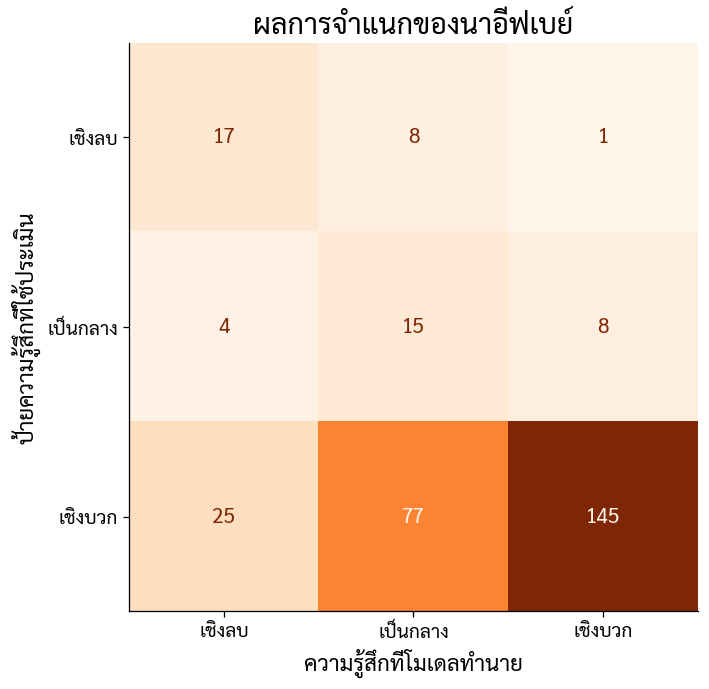

เชิงลบ: ทายตรงกับป้าย 17 จาก 26 รีวิว
เป็นกลาง: ทายตรงกับป้าย 15 จาก 27 รีวิว
เชิงบวก: ทายตรงกับป้าย 145 จาก 247 รีวิว


In [ ]:
fig, ax = plt.subplots(figsize=(7.7, 6.2))
ConfusionMatrixDisplay.from_predictions(data.label, data['Naive Bayes_prediction'],
    labels=CLASSES, display_labels=[SENTIMENT_TH[c] for c in CLASSES], ax=ax,
    colorbar=False, cmap="Oranges", values_format="d")
ax.set(title="ผลการจำแนกของนาอีฟเบย์", xlabel="ความรู้สึกที่โมเดลทำนาย", ylabel="ป้ายความรู้สึกที่ใช้ประเมิน")
save_plot("07_confusion_th")
for cls in CLASSES:
    subset = data[data.label == cls]
    correct = int((subset['Naive Bayes_prediction'] == cls).sum())
    print(f"{SENTIMENT_TH[cls]}: ทายตรงกับป้าย {correct} จาก {len(subset)} รีวิว")


## ภาพที่ 8 ตารางทายถูกและทายผิดของโลจิสติกรีเกรสชัน

**คำถาม:** โมเดลสับสนระหว่างความรู้สึกกลุ่มใด?

**วิธีอ่าน:** แกนตั้งคือป้ายที่ใช้ประเมิน แกนนอนคือผลทำนาย ช่องแนวทแยงคือทายตรงกับป้าย ตัวเลขคือจำนวนรีวิว

**แนวทางอธิบาย:** ชี้ผลของกลุ่มลบและกลางแยกจากกลุ่มบวก โดยใช้คำว่าป้ายต้นทางแทนการรับรองว่าป้ายเดิมเป็นความจริงแน่นอน

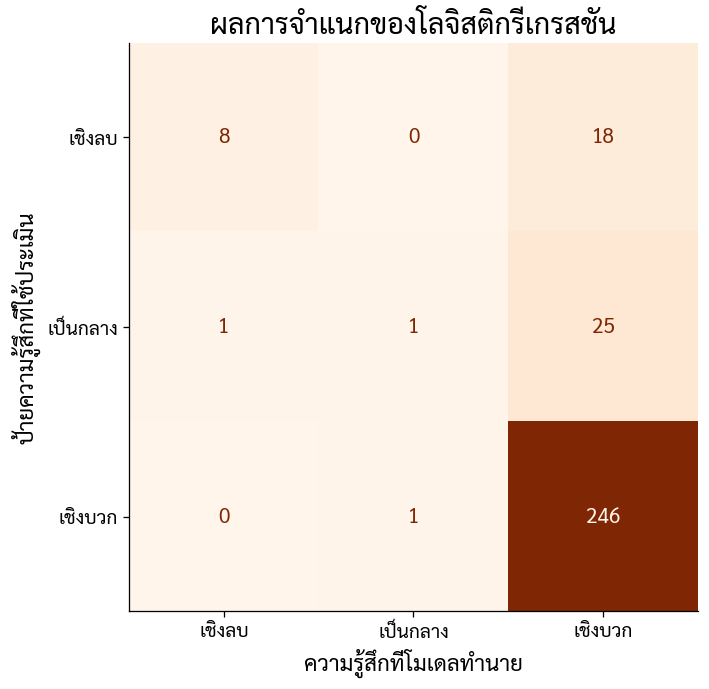

เชิงลบ: ทายตรงกับป้าย 8 จาก 26 รีวิว
เป็นกลาง: ทายตรงกับป้าย 1 จาก 27 รีวิว
เชิงบวก: ทายตรงกับป้าย 246 จาก 247 รีวิว


In [ ]:
fig, ax = plt.subplots(figsize=(7.7, 6.2))
ConfusionMatrixDisplay.from_predictions(data.label, data['Logistic Regression_prediction'],
    labels=CLASSES, display_labels=[SENTIMENT_TH[c] for c in CLASSES], ax=ax,
    colorbar=False, cmap="Oranges", values_format="d")
ax.set(title="ผลการจำแนกของโลจิสติกรีเกรสชัน", xlabel="ความรู้สึกที่โมเดลทำนาย", ylabel="ป้ายความรู้สึกที่ใช้ประเมิน")
save_plot("08_confusion_th")
for cls in CLASSES:
    subset = data[data.label == cls]
    correct = int((subset['Logistic Regression_prediction'] == cls).sum())
    print(f"{SENTIMENT_TH[cls]}: ทายตรงกับป้าย {correct} จาก {len(subset)} รีวิว")


## ภาพที่ 9 ความสัมพันธ์ดาวกับข้อความจากนาอีฟเบย์

**คำถาม:** เมื่อดาวสูงขึ้น คะแนนความรู้สึกจากข้อความสูงขึ้นด้วยหรือไม่?

**วิธีอ่าน:** แกนนอนคือดาว แกนตั้งคือคะแนนข้อความ −1 ถึง 1 แต่ละจุดคือรีวิว เส้นดำคือค่าเฉลี่ยที่แต่ละระดับดาว จุดถูกเลื่อนแนวนอนเล็กน้อยเพื่อไม่ให้ทับกัน

**แนวทางอธิบาย:** อธิบายทิศทางและค่าเพียร์สันจากข้อความใต้ภาพ ความสัมพันธ์ทางบวกไม่ใช่หลักฐานเหตุและผล และยังต้องตรวจความเป็นอิสระของป้าย

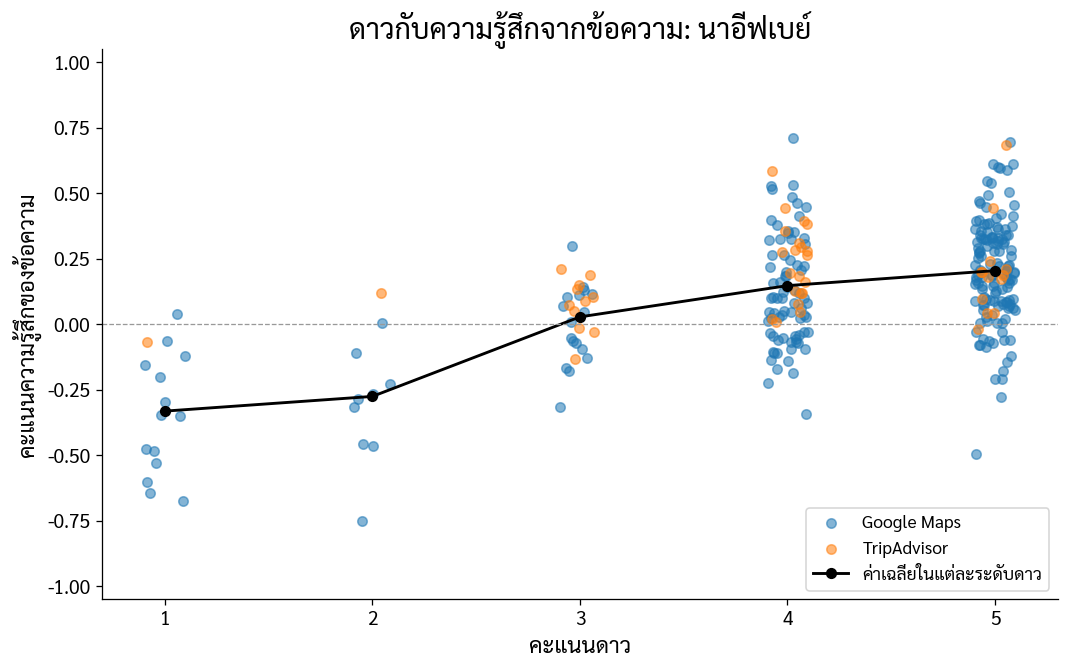

เพียร์สัน = 0.559 | สเปียร์แมน = 0.426 | 300 รีวิว
คะแนนข้อความ = ความน่าจะเป็นกลุ่มบวก ลบด้วยความน่าจะเป็นกลุ่มลบจากโมเดล เป็นดัชนีที่ยังไม่ได้ปรับเทียบ


In [ ]:
name = 'Naive Bayes'
fig, ax = plt.subplots(figsize=(9.5, 6))
jitter = np.random.default_rng(SEED).uniform(-.10, .10, len(data))
for j, platform in enumerate(sorted(data.platform.unique())):
    mask = data.platform == platform
    ax.scatter(data.loc[mask, "stars"] + jitter[mask], data.loc[mask, name+"_score"],
               s=35, alpha=.55, label=platform, color=plt.cm.tab10(j % 10))
means = data.groupby("stars")[name+"_score"].mean()
ax.plot(means.index, means.values, "k-o", linewidth=1.8, label="ค่าเฉลี่ยในแต่ละระดับดาว")
ax.axhline(0, color="#999999", linewidth=.8, linestyle="--")
ax.set(title="ดาวกับความรู้สึกจากข้อความ: นาอีฟเบย์", xlabel="คะแนนดาว",
       ylabel="คะแนนความรู้สึกของข้อความ", xticks=range(1,6), ylim=(-1.05,1.05))
ax.legend(loc="lower right", fontsize=11)
save_plot("09_relationship_th")
summary = correlations(data.stars, data[name+"_score"])
print(f"เพียร์สัน = {summary['pearson_r']:.3f} | สเปียร์แมน = {summary['spearman_rho']:.3f} | {summary['n']} รีวิว")
print("คะแนนข้อความ = ความน่าจะเป็นกลุ่มบวก ลบด้วยความน่าจะเป็นกลุ่มลบจากโมเดล เป็นดัชนีที่ยังไม่ได้ปรับเทียบ")


## ภาพที่ 10 ความสัมพันธ์ดาวกับข้อความจากโลจิสติกรีเกรสชัน

**คำถาม:** เมื่อดาวสูงขึ้น คะแนนความรู้สึกจากข้อความสูงขึ้นด้วยหรือไม่?

**วิธีอ่าน:** แกนนอนคือดาว แกนตั้งคือคะแนนข้อความ −1 ถึง 1 แต่ละจุดคือรีวิว เส้นดำคือค่าเฉลี่ยที่แต่ละระดับดาว จุดถูกเลื่อนแนวนอนเล็กน้อยเพื่อไม่ให้ทับกัน

**แนวทางอธิบาย:** อธิบายทิศทางและค่าเพียร์สันจากข้อความใต้ภาพ ความสัมพันธ์ทางบวกไม่ใช่หลักฐานเหตุและผล และยังต้องตรวจความเป็นอิสระของป้าย

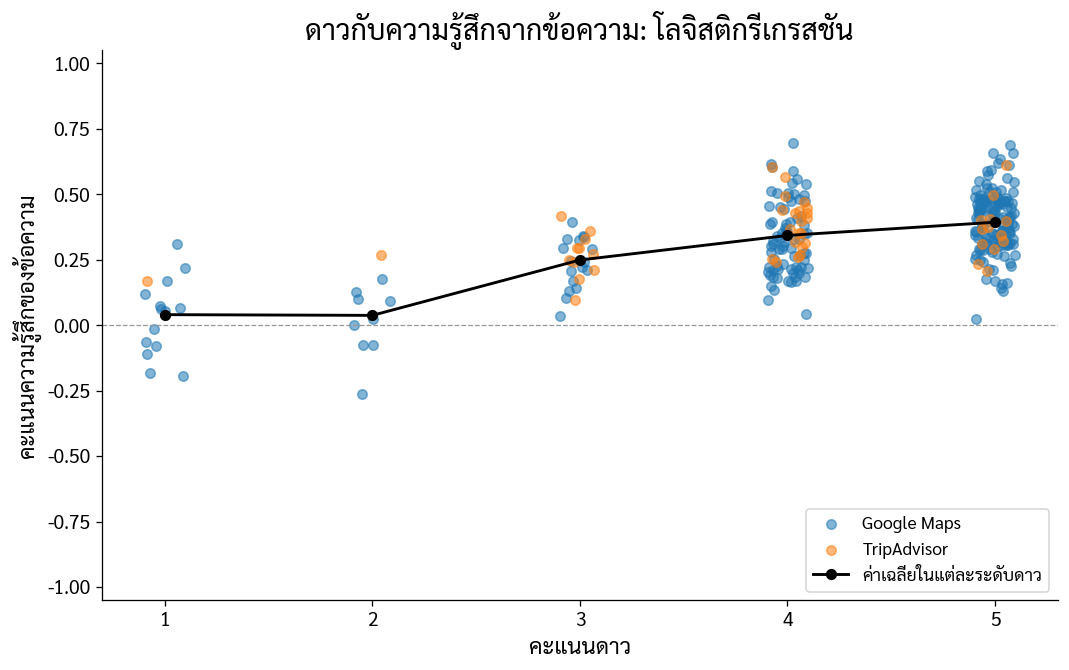

เพียร์สัน = 0.609 | สเปียร์แมน = 0.485 | 300 รีวิว
คะแนนข้อความ = ความน่าจะเป็นกลุ่มบวก ลบด้วยความน่าจะเป็นกลุ่มลบจากโมเดล เป็นดัชนีที่ยังไม่ได้ปรับเทียบ


In [ ]:
name = 'Logistic Regression'
fig, ax = plt.subplots(figsize=(9.5, 6))
jitter = np.random.default_rng(SEED).uniform(-.10, .10, len(data))
for j, platform in enumerate(sorted(data.platform.unique())):
    mask = data.platform == platform
    ax.scatter(data.loc[mask, "stars"] + jitter[mask], data.loc[mask, name+"_score"],
               s=35, alpha=.55, label=platform, color=plt.cm.tab10(j % 10))
means = data.groupby("stars")[name+"_score"].mean()
ax.plot(means.index, means.values, "k-o", linewidth=1.8, label="ค่าเฉลี่ยในแต่ละระดับดาว")
ax.axhline(0, color="#999999", linewidth=.8, linestyle="--")
ax.set(title="ดาวกับความรู้สึกจากข้อความ: โลจิสติกรีเกรสชัน", xlabel="คะแนนดาว",
       ylabel="คะแนนความรู้สึกของข้อความ", xticks=range(1,6), ylim=(-1.05,1.05))
ax.legend(loc="lower right", fontsize=11)
save_plot("10_relationship_th")
summary = correlations(data.stars, data[name+"_score"])
print(f"เพียร์สัน = {summary['pearson_r']:.3f} | สเปียร์แมน = {summary['spearman_rho']:.3f} | {summary['n']} รีวิว")
print("คะแนนข้อความ = ความน่าจะเป็นกลุ่มบวก ลบด้วยความน่าจะเป็นกลุ่มลบจากโมเดล เป็นดัชนีที่ยังไม่ได้ปรับเทียบ")


## ภาพที่ 11 ความรู้สึกในแต่ละระดับดาวจากนาอีฟเบย์

**คำถาม:** รีวิวที่ให้ดาวเท่ากันถูกทำนายเป็นความรู้สึกแบบใดบ้าง?

**วิธีอ่าน:** แต่ละแถวคือระดับดาว แต่ละคอลัมน์คือความรู้สึกที่ทำนาย ร้อยละรวมภายในแต่ละแถวเท่ากับ 100 หากมีรีวิว สีเข้มหมายถึงสัดส่วนมาก

**แนวทางอธิบาย:** ตรวจว่ามีดาวสูงแต่ข้อความถูกทำนายเป็นลบ หรือดาวต่ำแต่ทำนายเป็นบวกหรือไม่ กรณีเหล่านี้ต้องอ่านทบทวนเพราะโมเดลอาจผิด

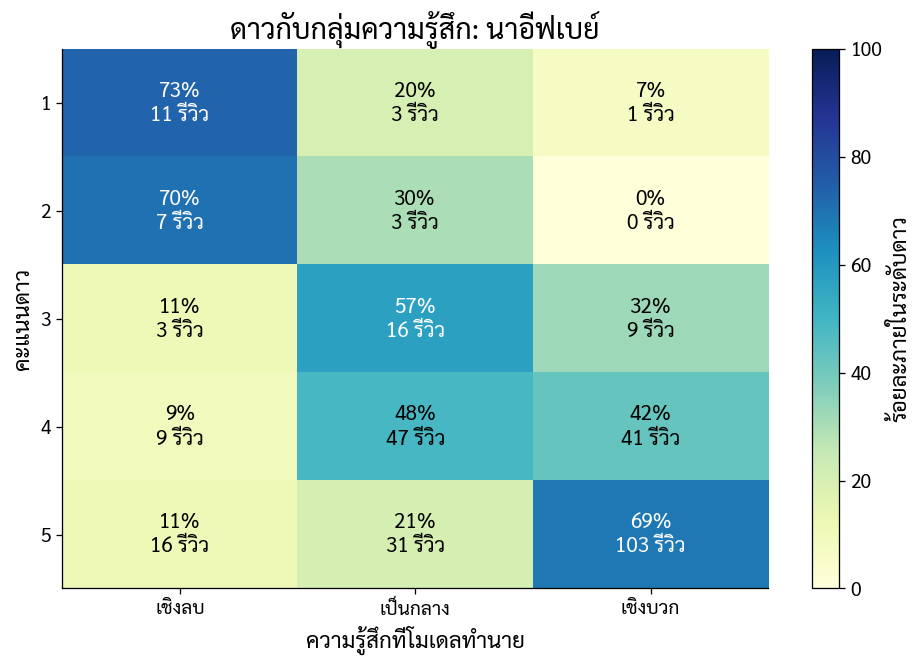

จำนวนและร้อยละในภาพเป็นผลทำนายของโมเดล ไม่ใช่การยืนยันว่าดาวกับข้อความขัดแย้งกันจริง


In [ ]:
ct = pd.crosstab(data.stars, data['Naive Bayes_prediction']).reindex(index=range(1,6), columns=CLASSES, fill_value=0)
pct = ct.div(ct.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)*100
fig, ax = plt.subplots(figsize=(8.5, 6))
im = ax.imshow(pct.to_numpy(), vmin=0, vmax=100, cmap="YlGnBu", aspect="auto")
for i in range(5):
    for j in range(3):
        ax.text(j, i, f"{pct.iloc[i,j]:.0f}%\n{ct.iloc[i,j]} รีวิว", ha="center", va="center",
                color="white" if pct.iloc[i,j]>55 else "black", fontsize=13)
ax.set(xticks=range(3), xticklabels=[SENTIMENT_TH[c] for c in CLASSES],
       yticks=range(5), yticklabels=range(1,6), xlabel="ความรู้สึกที่โมเดลทำนาย", ylabel="คะแนนดาว",
       title="ดาวกับกลุ่มความรู้สึก: นาอีฟเบย์")
fig.colorbar(im, ax=ax, label="ร้อยละภายในระดับดาว")
save_plot("11_heatmap_th")
print("จำนวนและร้อยละในภาพเป็นผลทำนายของโมเดล ไม่ใช่การยืนยันว่าดาวกับข้อความขัดแย้งกันจริง")


## ภาพที่ 12 ความรู้สึกในแต่ละระดับดาวจากโลจิสติกรีเกรสชัน

**คำถาม:** รีวิวที่ให้ดาวเท่ากันถูกทำนายเป็นความรู้สึกแบบใดบ้าง?

**วิธีอ่าน:** แต่ละแถวคือระดับดาว แต่ละคอลัมน์คือความรู้สึกที่ทำนาย ร้อยละรวมภายในแต่ละแถวเท่ากับ 100 หากมีรีวิว สีเข้มหมายถึงสัดส่วนมาก

**แนวทางอธิบาย:** ตรวจว่ามีดาวสูงแต่ข้อความถูกทำนายเป็นลบ หรือดาวต่ำแต่ทำนายเป็นบวกหรือไม่ กรณีเหล่านี้ต้องอ่านทบทวนเพราะโมเดลอาจผิด

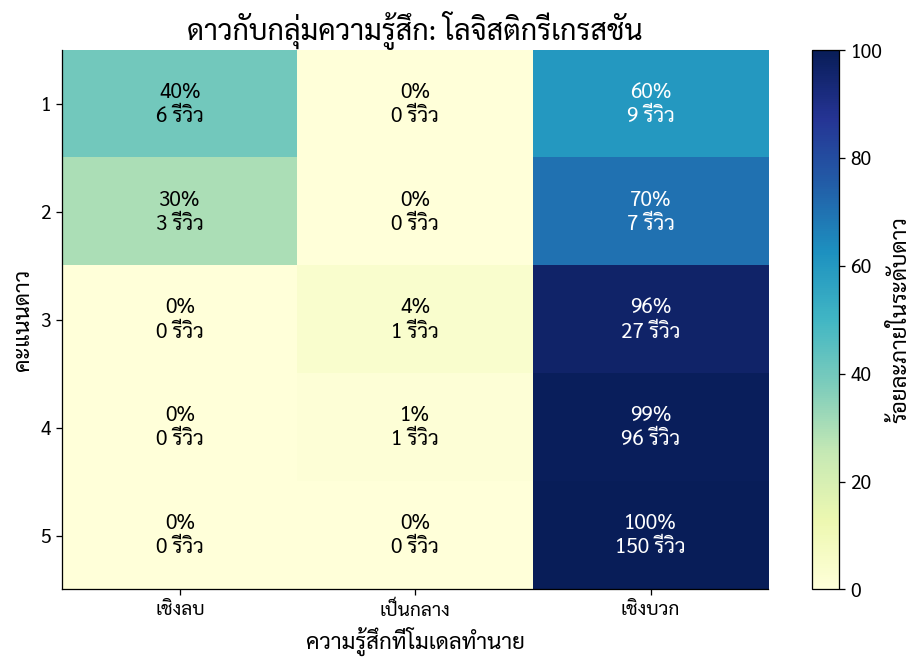

จำนวนและร้อยละในภาพเป็นผลทำนายของโมเดล ไม่ใช่การยืนยันว่าดาวกับข้อความขัดแย้งกันจริง


In [ ]:
ct = pd.crosstab(data.stars, data['Logistic Regression_prediction']).reindex(index=range(1,6), columns=CLASSES, fill_value=0)
pct = ct.div(ct.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)*100
fig, ax = plt.subplots(figsize=(8.5, 6))
im = ax.imshow(pct.to_numpy(), vmin=0, vmax=100, cmap="YlGnBu", aspect="auto")
for i in range(5):
    for j in range(3):
        ax.text(j, i, f"{pct.iloc[i,j]:.0f}%\n{ct.iloc[i,j]} รีวิว", ha="center", va="center",
                color="white" if pct.iloc[i,j]>55 else "black", fontsize=13)
ax.set(xticks=range(3), xticklabels=[SENTIMENT_TH[c] for c in CLASSES],
       yticks=range(5), yticklabels=range(1,6), xlabel="ความรู้สึกที่โมเดลทำนาย", ylabel="คะแนนดาว",
       title="ดาวกับกลุ่มความรู้สึก: โลจิสติกรีเกรสชัน")
fig.colorbar(im, ax=ax, label="ร้อยละภายในระดับดาว")
save_plot("12_heatmap_th")
print("จำนวนและร้อยละในภาพเป็นผลทำนายของโมเดล ไม่ใช่การยืนยันว่าดาวกับข้อความขัดแย้งกันจริง")


# ประเด็นที่นักท่องเที่ยวกล่าวถึง แยกทีละเรื่อง

แต่ละภาพด้านล่างแสดง **การกระจายดาวของรีวิวที่กล่าวถึงประเด็นเดียว** เช่น สัตว์ ราคา หรือการบริการ จึงอธิบายทีละเรื่องได้โดยไม่รวมแท่งของหลายประเด็นในภาพเดียว

ใต้ภาพจะสรุปจำนวนรีวิว สัดส่วนจากข้อมูลทั้งหมด ดาวเฉลี่ย และความสัมพันธ์ของดาวกับคะแนนข้อความจากแต่ละโมเดลภายในกลุ่ม หากข้อมูลน้อยหรือไม่มีความแปรปรวน จะแจ้งว่าคำนวณความสัมพันธ์ไม่ได้

หนึ่งรีวิวอาจอยู่ในหลายประเด็นได้ **ดาวเป็นคะแนนรวมของรีวิว ไม่ใช่คะแนนเฉพาะประเด็นนั้น** เช่น รีวิวพูดทั้งราคาและสัตว์ เราจะยังบอกไม่ได้ว่าดาวต่ำเพราะราคาเพียงอย่างเดียว


In [ ]:
def plot_one_topic(topic, figure_number):
    d = df[df.topics.map(lambda tags: topic in tags)]
    if d.empty:
        print(f"ไม่พบแท็กประเด็น {topic} ในไฟล์นี้")
        return
    counts = d.stars.value_counts().reindex(range(1,6), fill_value=0)
    fig, ax = plt.subplots(figsize=(9, 5.3))
    bars = ax.bar(counts.index, counts.values, color="#438d83")
    ax.bar_label(bars, padding=4)
    ax.set(title=f"คะแนนดาวของรีวิวที่กล่าวถึง{topic}", xlabel="คะแนนดาว",
           ylabel="จำนวนรีวิว", xticks=range(1,6), ylim=(0, max(1, counts.max())*1.22))
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    save_plot(f"{figure_number:02d}_topic_{topic}")
    print(f"ประเด็น {topic}: {len(d):,} รีวิว คิดเป็น {len(d)/len(df):.1%} ของรีวิวทั้งหมด")
    print(f"คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = {d.stars.mean():.2f} จาก 5 ดาว")
    labeled = data[data.topics.map(lambda tags: topic in tags)]
    if len(labeled) >= 10:
        for name in model_names[:2]:
            result = correlations(labeled.stars, labeled[name+"_score"])
            if np.isfinite(result["pearson_r"]):
                print(f"{MODEL_TH[name]}: เพียร์สันภายในประเด็นนี้ = {result['pearson_r']:.3f} ({len(labeled)} รีวิว)")
            else:
                print(f"{MODEL_TH[name]}: คำนวณความสัมพันธ์ไม่ได้ เพราะคะแนนไม่มีความแปรปรวน")
    else:
        print("มีรีวิวพร้อมป้ายน้อยกว่า 10 รายการ จึงไม่รายงานความสัมพันธ์ภายในประเด็น")
    print("การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ")


## ภาพที่ 13 ประเด็นสัตว์

**คำถาม:** รีวิวที่กล่าวถึงสัตว์ให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงสัตว์ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

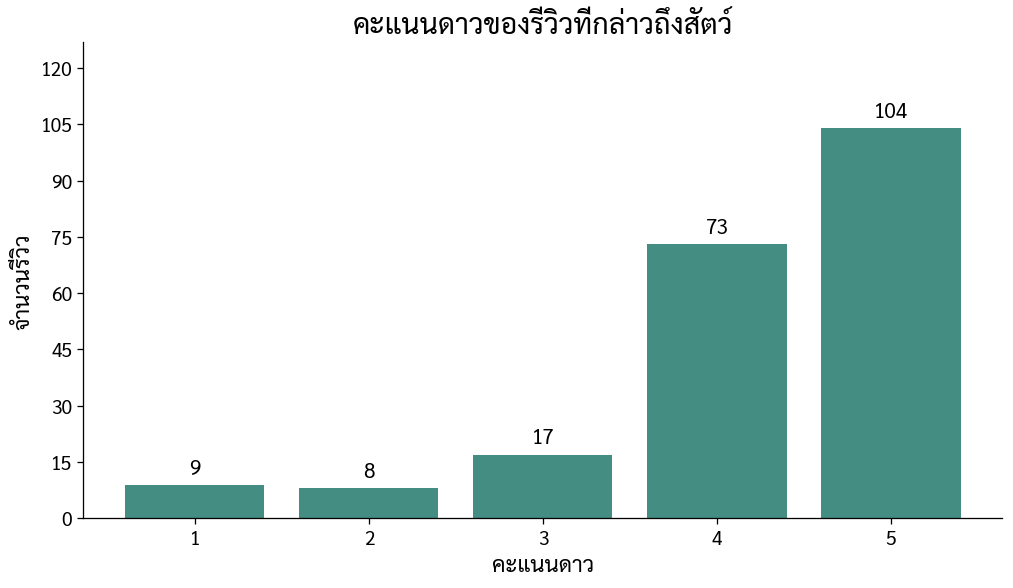

ประเด็น สัตว์: 211 รีวิว คิดเป็น 70.3% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.21 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.560 (211 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.602 (211 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('สัตว์', 13)


## ภาพที่ 14 ประเด็นครอบครัว

**คำถาม:** รีวิวที่กล่าวถึงครอบครัวให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงครอบครัว มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

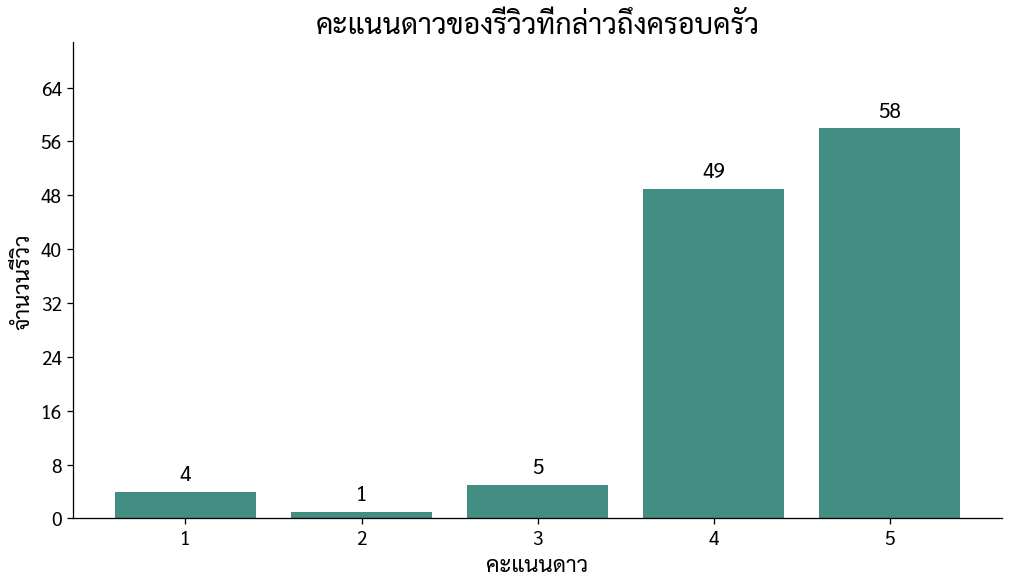

ประเด็น ครอบครัว: 117 รีวิว คิดเป็น 39.0% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.33 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.529 (117 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.560 (117 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ครอบครัว', 14)


## ภาพที่ 15 ประเด็นความประทับใจ

**คำถาม:** รีวิวที่กล่าวถึงความประทับใจให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงความประทับใจ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

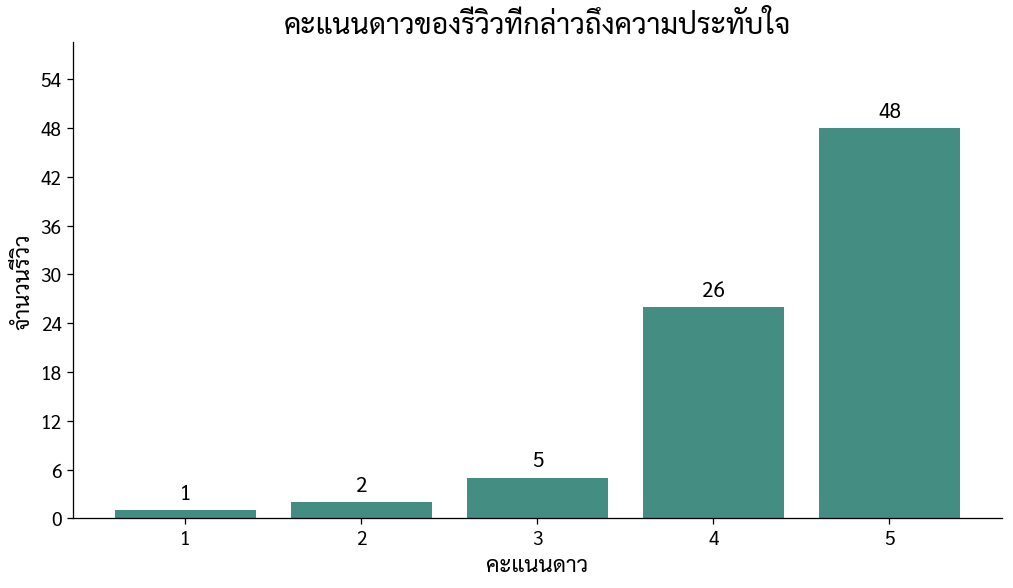

ประเด็น ความประทับใจ: 82 รีวิว คิดเป็น 27.3% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.44 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.491 (82 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.537 (82 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ความประทับใจ', 15)


## ภาพที่ 16 ประเด็นการแสดง

**คำถาม:** รีวิวที่กล่าวถึงการแสดงให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงการแสดง มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

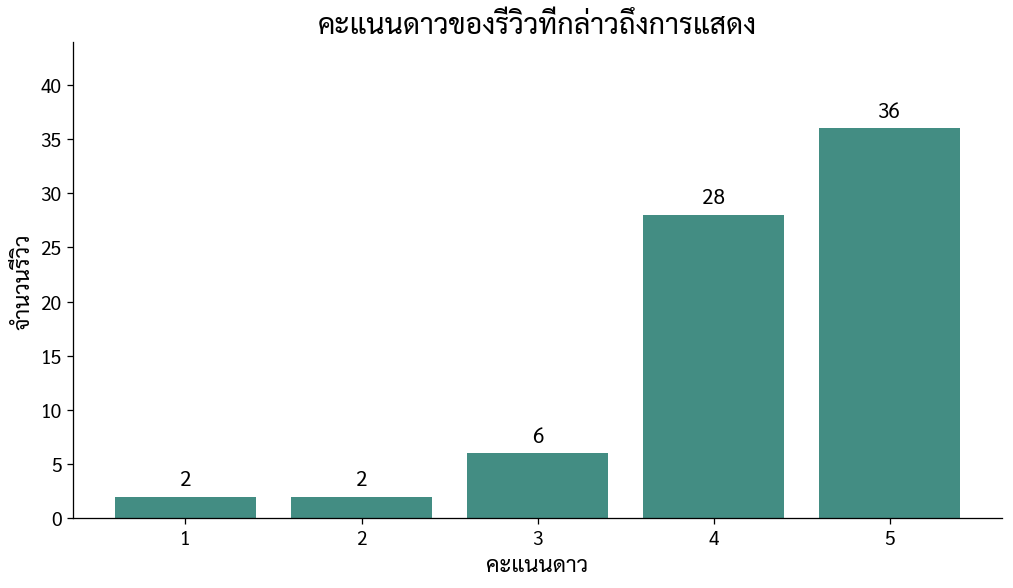

ประเด็น การแสดง: 74 รีวิว คิดเป็น 24.7% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.27 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.468 (74 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.535 (74 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('การแสดง', 16)


## ภาพที่ 17 ประเด็นบรรยากาศ

**คำถาม:** รีวิวที่กล่าวถึงบรรยากาศให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงบรรยากาศ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

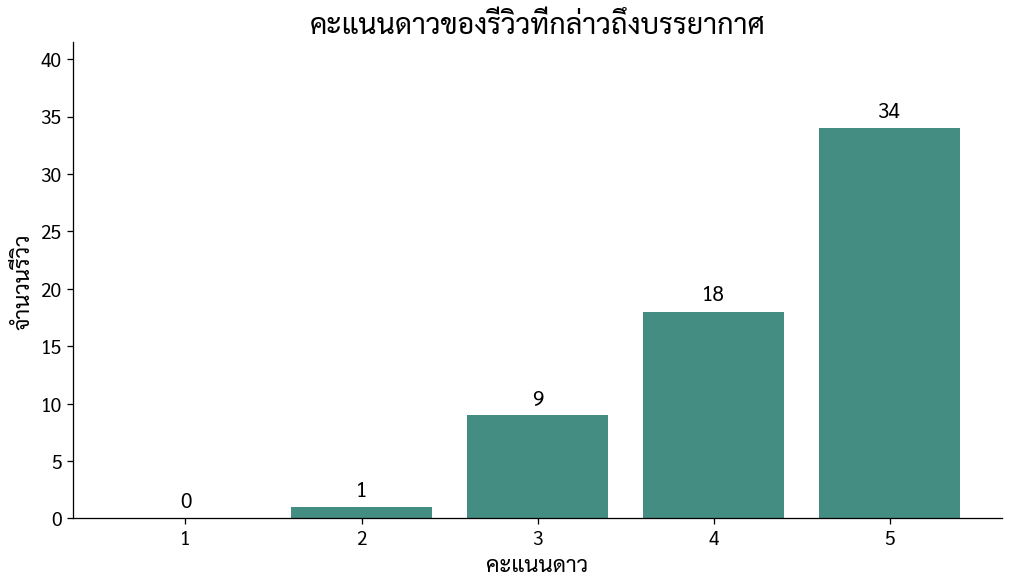

ประเด็น บรรยากาศ: 62 รีวิว คิดเป็น 20.7% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.37 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.411 (62 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.483 (62 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('บรรยากาศ', 17)


## ภาพที่ 18 ประเด็นการเดินทาง

**คำถาม:** รีวิวที่กล่าวถึงการเดินทางให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงการเดินทาง มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

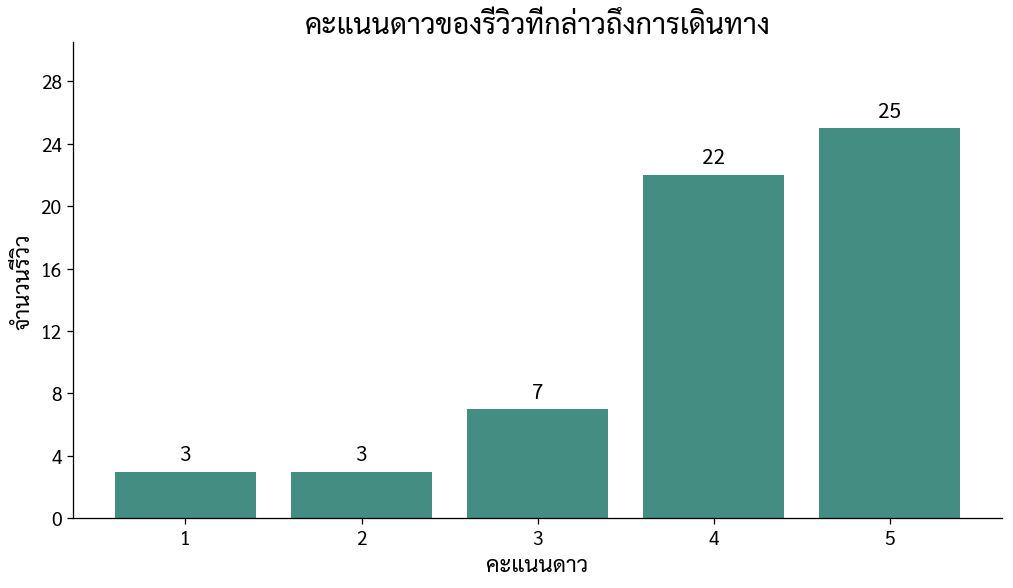

ประเด็น การเดินทาง: 60 รีวิว คิดเป็น 20.0% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.05 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.614 (60 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.654 (60 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('การเดินทาง', 18)


## ภาพที่ 19 ประเด็นการบริการ

**คำถาม:** รีวิวที่กล่าวถึงการบริการให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงการบริการ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

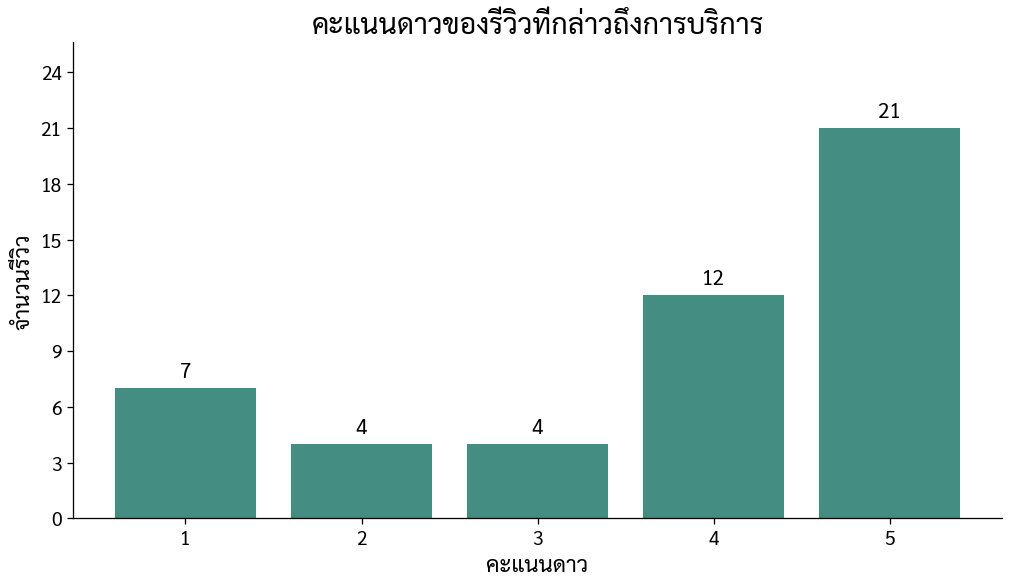

ประเด็น การบริการ: 48 รีวิว คิดเป็น 16.0% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.75 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.590 (48 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.645 (48 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('การบริการ', 19)


## ภาพที่ 20 ประเด็นราคา

**คำถาม:** รีวิวที่กล่าวถึงราคาให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงราคา มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

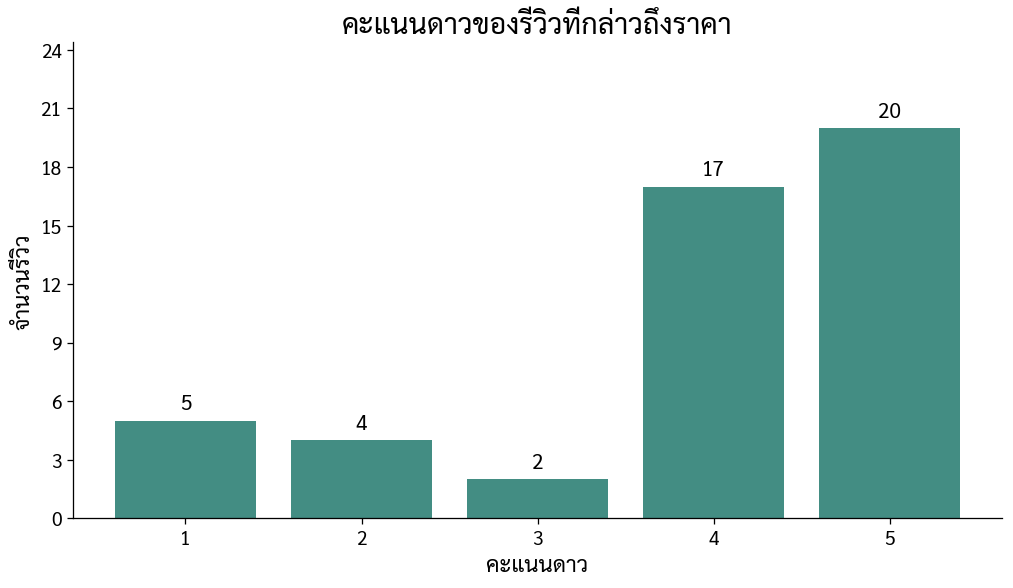

ประเด็น ราคา: 48 รีวิว คิดเป็น 16.0% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.90 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.780 (48 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.836 (48 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ราคา', 20)


## ภาพที่ 21 ประเด็นจำนวนสัตว์

**คำถาม:** รีวิวที่กล่าวถึงจำนวนสัตว์ให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงจำนวนสัตว์ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

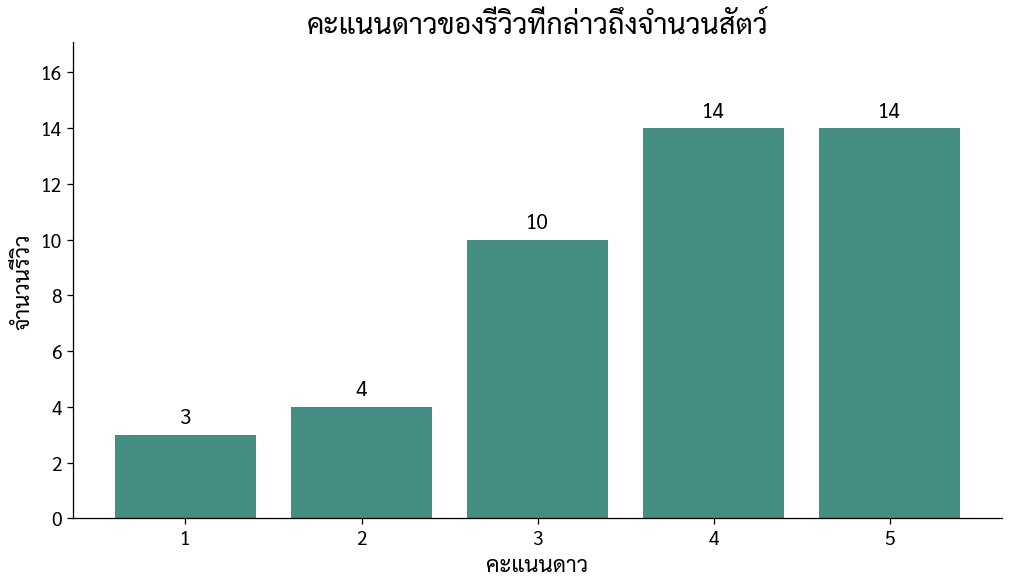

ประเด็น จำนวนสัตว์: 45 รีวิว คิดเป็น 15.0% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.71 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.653 (45 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.671 (45 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('จำนวนสัตว์', 21)


## ภาพที่ 22 ประเด็นสวนน้ำ

**คำถาม:** รีวิวที่กล่าวถึงสวนน้ำให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงสวนน้ำ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

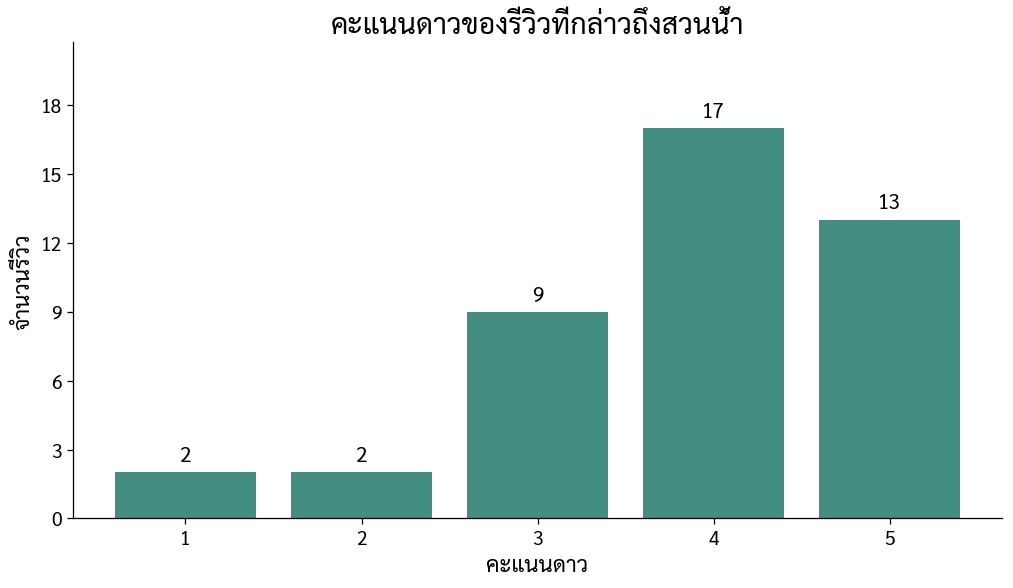

ประเด็น สวนน้ำ: 43 รีวิว คิดเป็น 14.3% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.86 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.564 (43 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.592 (43 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('สวนน้ำ', 22)


## ภาพที่ 23 ประเด็นวิว

**คำถาม:** รีวิวที่กล่าวถึงวิวให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงวิว มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

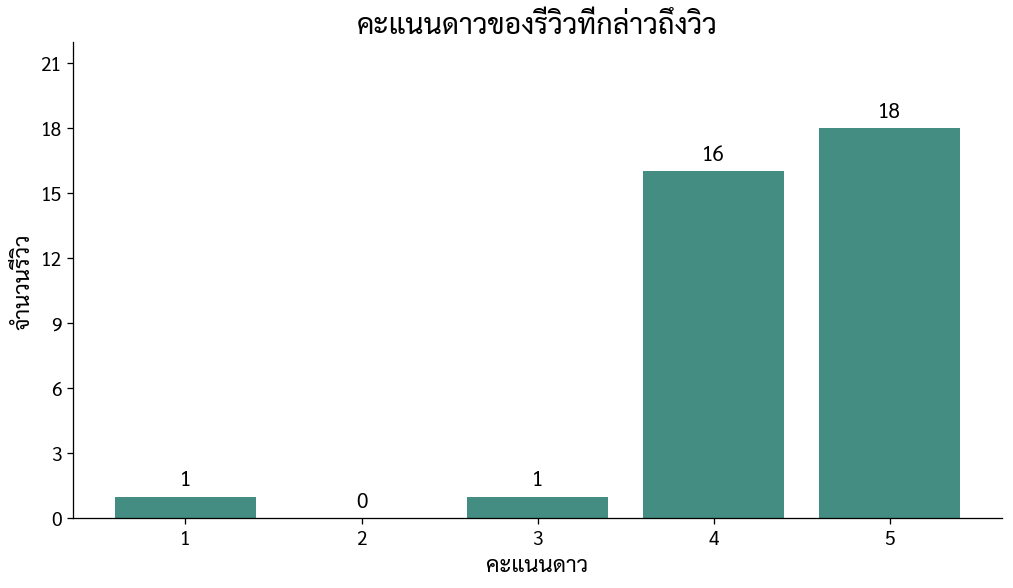

ประเด็น วิว: 36 รีวิว คิดเป็น 12.0% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.39 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.602 (36 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.605 (36 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('วิว', 23)


## ภาพที่ 24 ประเด็นกิจกรรม

**คำถาม:** รีวิวที่กล่าวถึงกิจกรรมให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงกิจกรรม มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

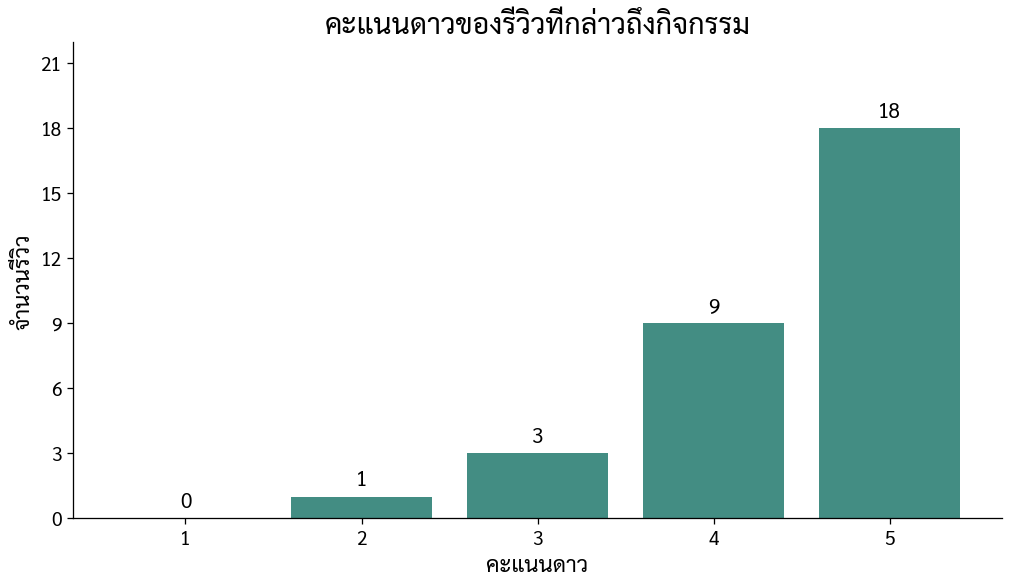

ประเด็น กิจกรรม: 31 รีวิว คิดเป็น 10.3% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.42 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.587 (31 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.621 (31 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('กิจกรรม', 24)


## ภาพที่ 25 ประเด็นสวัสดิภาพสัตว์

**คำถาม:** รีวิวที่กล่าวถึงสวัสดิภาพสัตว์ให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงสวัสดิภาพสัตว์ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

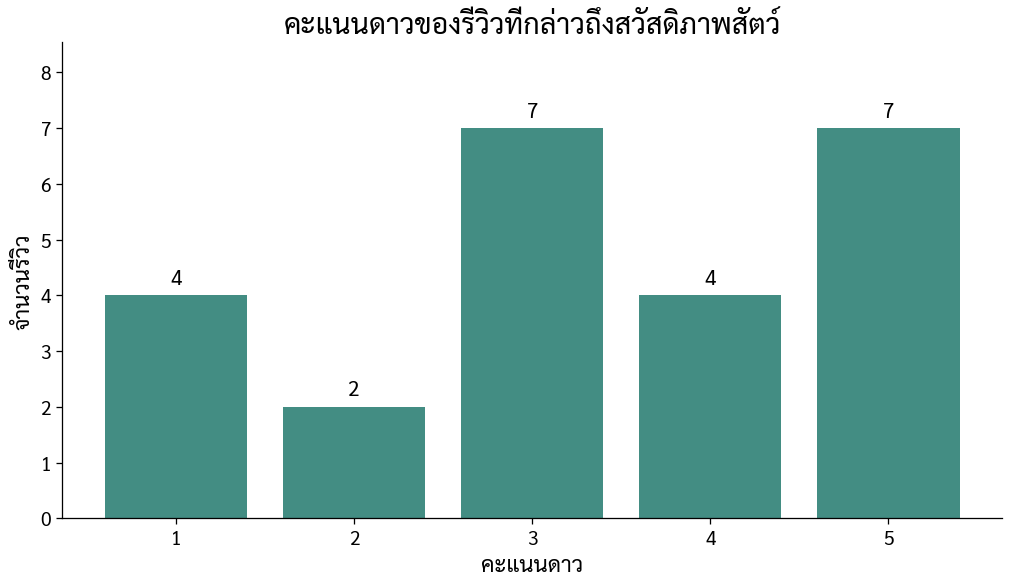

ประเด็น สวัสดิภาพสัตว์: 24 รีวิว คิดเป็น 8.0% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.33 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.605 (24 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.642 (24 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('สวัสดิภาพสัตว์', 25)


## ภาพที่ 26 ประเด็นอาหาร

**คำถาม:** รีวิวที่กล่าวถึงอาหารให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงอาหาร มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

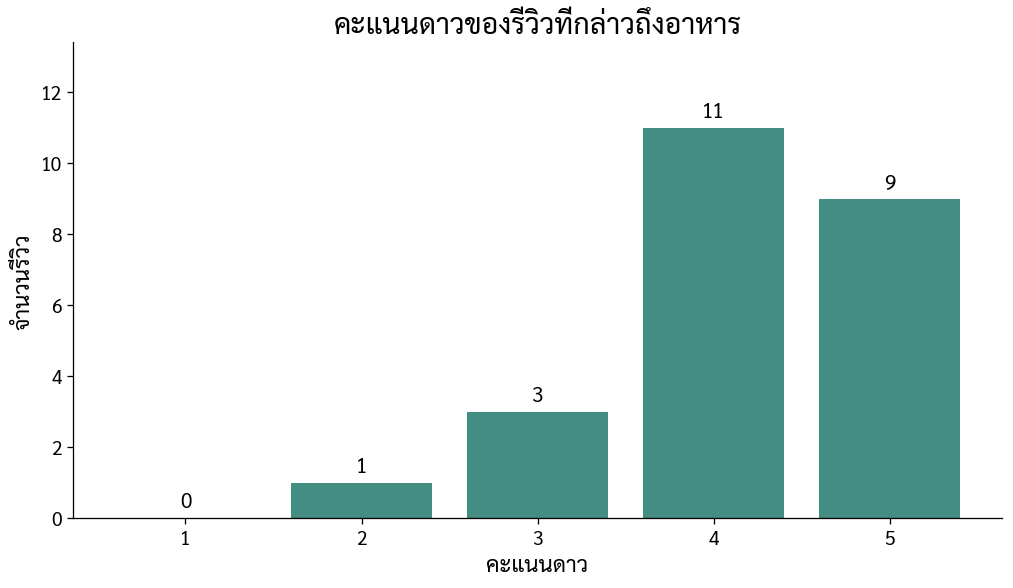

ประเด็น อาหาร: 24 รีวิว คิดเป็น 8.0% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.17 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.558 (24 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.629 (24 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('อาหาร', 26)


## ภาพที่ 27 ประเด็นการปรับปรุง

**คำถาม:** รีวิวที่กล่าวถึงการปรับปรุงให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงการปรับปรุง มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

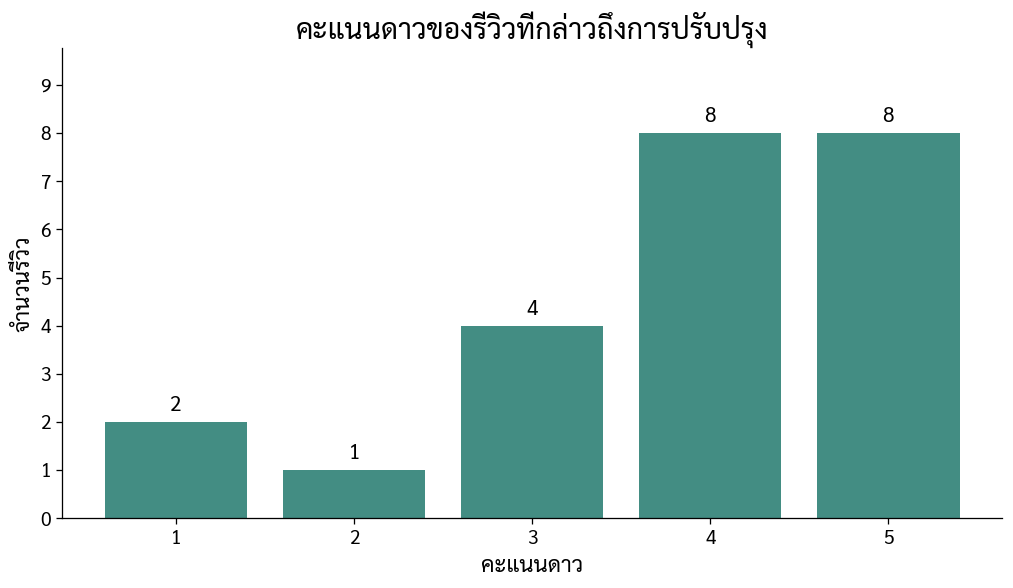

ประเด็น การปรับปรุง: 23 รีวิว คิดเป็น 7.7% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.83 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.727 (23 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.766 (23 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('การปรับปรุง', 27)


## ภาพที่ 28 ประเด็นความคิดเห็นทั่วไป

**คำถาม:** รีวิวที่กล่าวถึงความคิดเห็นทั่วไปให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงความคิดเห็นทั่วไป มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

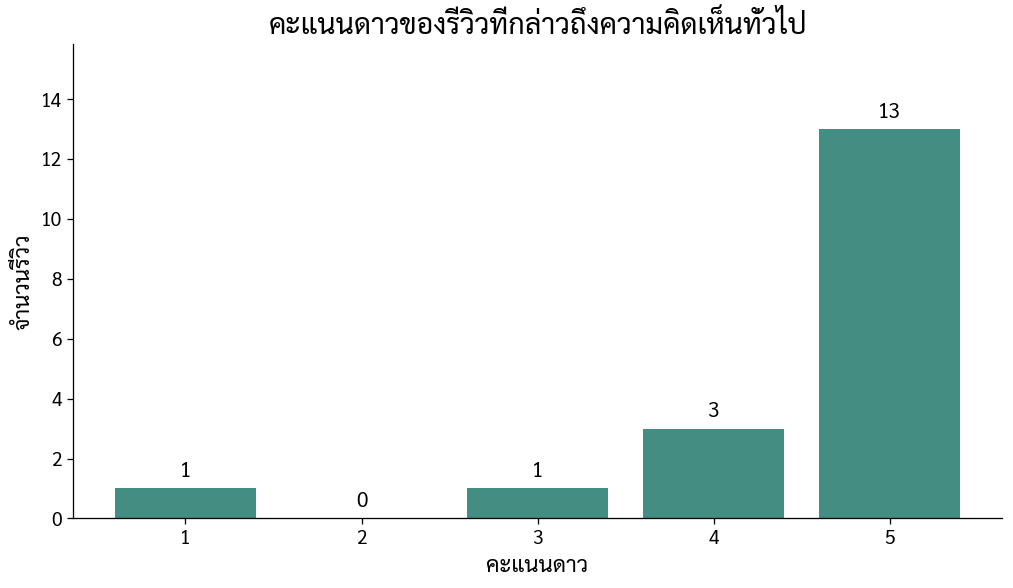

ประเด็น ความคิดเห็นทั่วไป: 18 รีวิว คิดเป็น 6.0% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.50 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.714 (18 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.725 (18 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ความคิดเห็นทั่วไป', 28)


## ภาพที่ 29 ประเด็นความสะอาด

**คำถาม:** รีวิวที่กล่าวถึงความสะอาดให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงความสะอาด มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

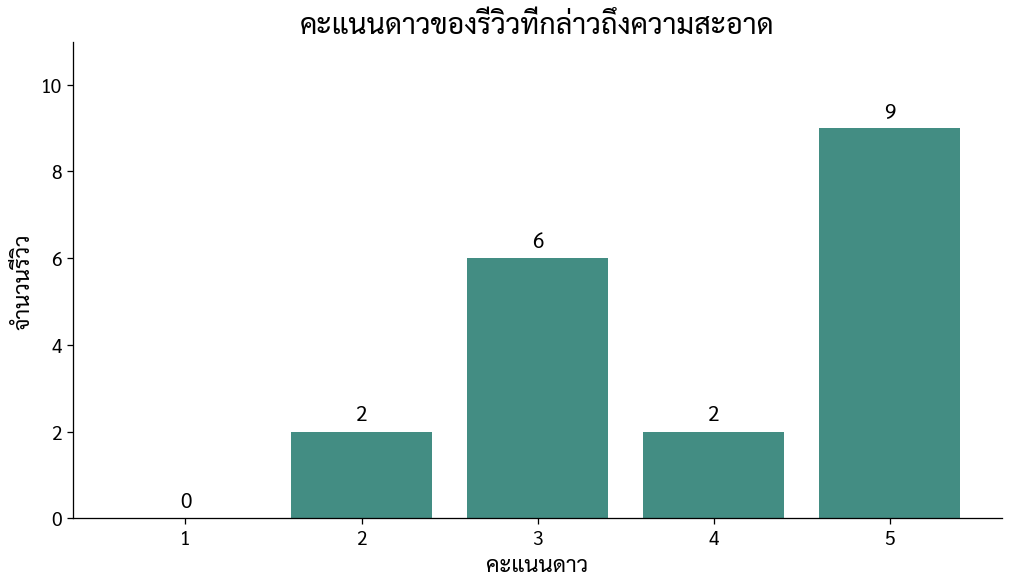

ประเด็น ความสะอาด: 19 รีวิว คิดเป็น 6.3% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.95 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.196 (19 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.301 (19 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ความสะอาด', 29)


## ภาพที่ 30 ประเด็นสิ่งอำนวยความสะดวก

**คำถาม:** รีวิวที่กล่าวถึงสิ่งอำนวยความสะดวกให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงสิ่งอำนวยความสะดวก มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

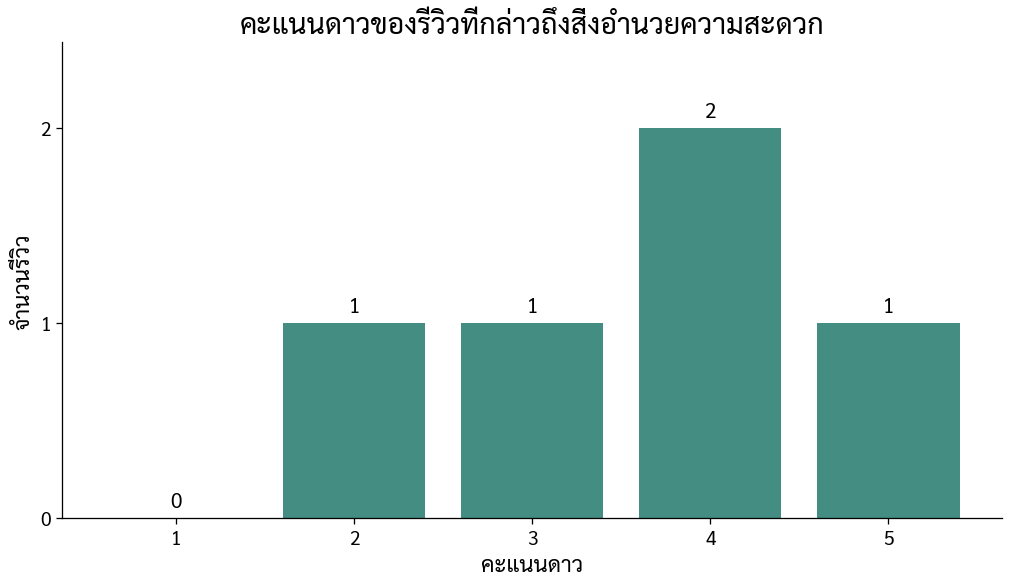

ประเด็น สิ่งอำนวยความสะดวก: 5 รีวิว คิดเป็น 1.7% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.60 จาก 5 ดาว
มีรีวิวพร้อมป้ายน้อยกว่า 10 รายการ จึงไม่รายงานความสัมพันธ์ภายในประเด็น
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('สิ่งอำนวยความสะดวก', 30)


## ภาพที่ 31 ประเด็นความรู้

**คำถาม:** รีวิวที่กล่าวถึงความรู้ให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงความรู้ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

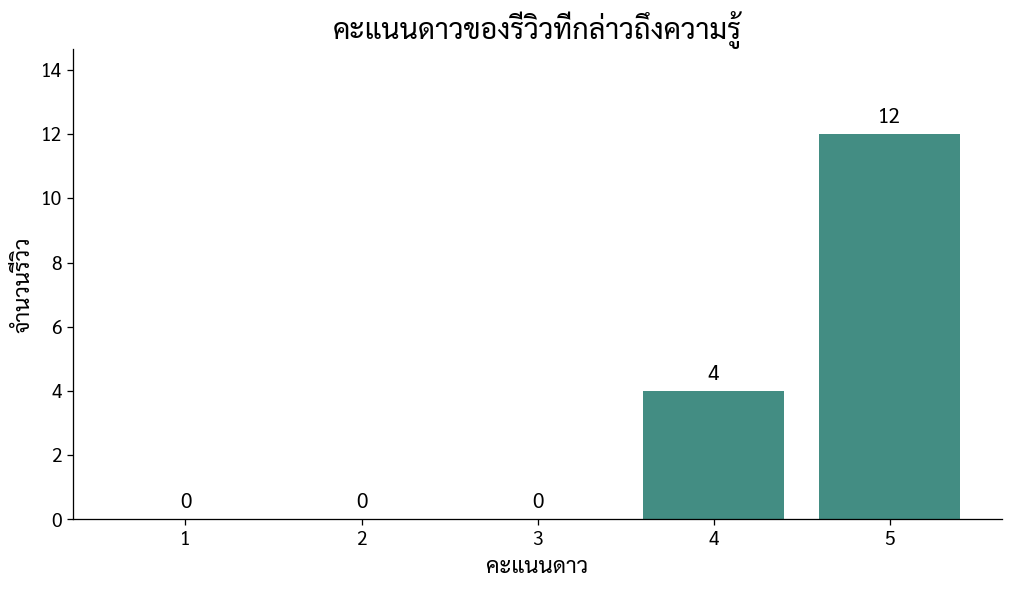

ประเด็น ความรู้: 16 รีวิว คิดเป็น 5.3% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.75 จาก 5 ดาว
นาอีฟเบย์: เพียร์สันภายในประเด็นนี้ = 0.065 (16 รีวิว)
โลจิสติกรีเกรสชัน: เพียร์สันภายในประเด็นนี้ = 0.188 (16 รีวิว)
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ความรู้', 31)


## ภาพที่ 32 ประเด็นความปลอดภัย

**คำถาม:** รีวิวที่กล่าวถึงความปลอดภัยให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงความปลอดภัย มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

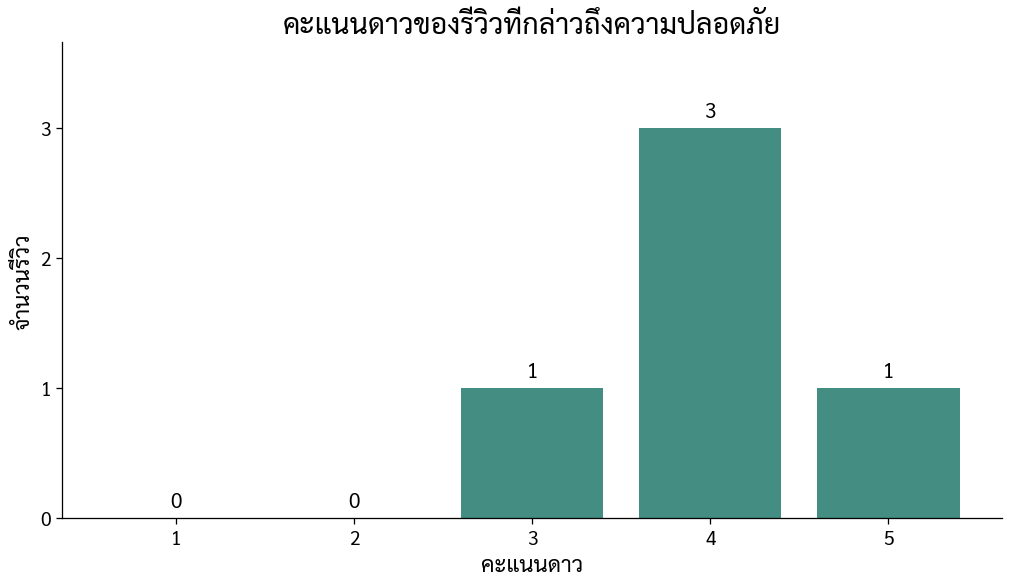

ประเด็น ความปลอดภัย: 5 รีวิว คิดเป็น 1.7% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.00 จาก 5 ดาว
มีรีวิวพร้อมป้ายน้อยกว่า 10 รายการ จึงไม่รายงานความสัมพันธ์ภายในประเด็น
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ความปลอดภัย', 32)


## ภาพที่ 33 ประเด็นที่จอดรถ

**คำถาม:** รีวิวที่กล่าวถึงที่จอดรถให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงที่จอดรถ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

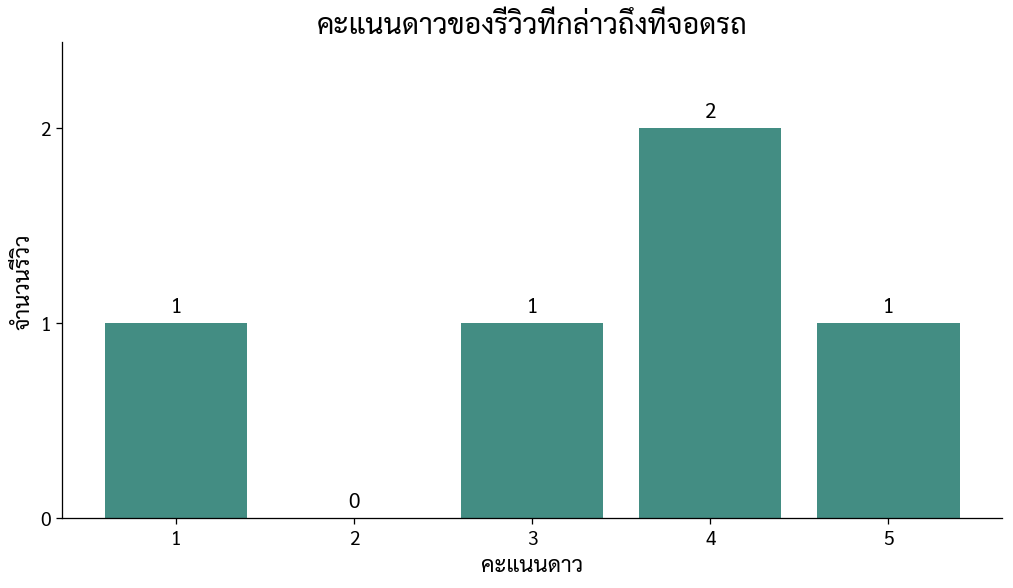

ประเด็น ที่จอดรถ: 5 รีวิว คิดเป็น 1.7% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.40 จาก 5 ดาว
มีรีวิวพร้อมป้ายน้อยกว่า 10 รายการ จึงไม่รายงานความสัมพันธ์ภายในประเด็น
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ที่จอดรถ', 33)


## ภาพที่ 34 ประเด็นห้องน้ำ

**คำถาม:** รีวิวที่กล่าวถึงห้องน้ำให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงห้องน้ำ มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

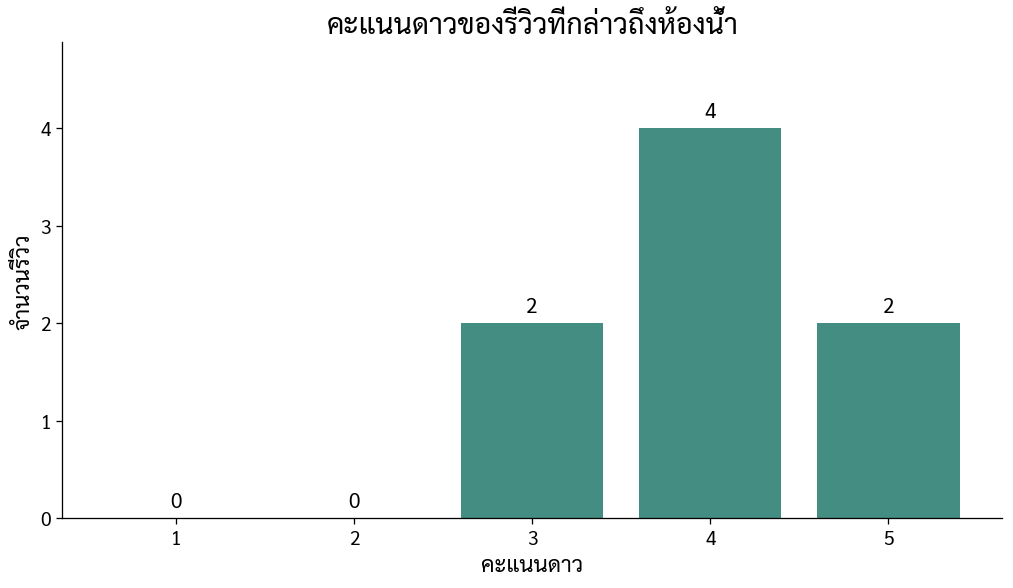

ประเด็น ห้องน้ำ: 8 รีวิว คิดเป็น 2.7% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 4.00 จาก 5 ดาว
มีรีวิวพร้อมป้ายน้อยกว่า 10 รายการ จึงไม่รายงานความสัมพันธ์ภายในประเด็น
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ห้องน้ำ', 34)


## ภาพที่ 35 ประเด็นที่พัก

**คำถาม:** รีวิวที่กล่าวถึงที่พักให้คะแนนดาวอย่างไร?

**วิธีอ่าน:** ดูจำนวนรีวิวในแต่ละระดับดาว แล้วอ่านจำนวนรวม ร้อยละ และดาวเฉลี่ยใต้ภาพ

**แนวทางอธิบาย:** “ในกลุ่มรีวิวที่กล่าวถึงที่พัก มีจำนวนและคะแนนดังที่แสดงใต้ภาพ” จากนั้นอธิบายการกระจายดาว โดยไม่สรุปว่าประเด็นนี้ทำให้ดาวสูงหรือต่ำ

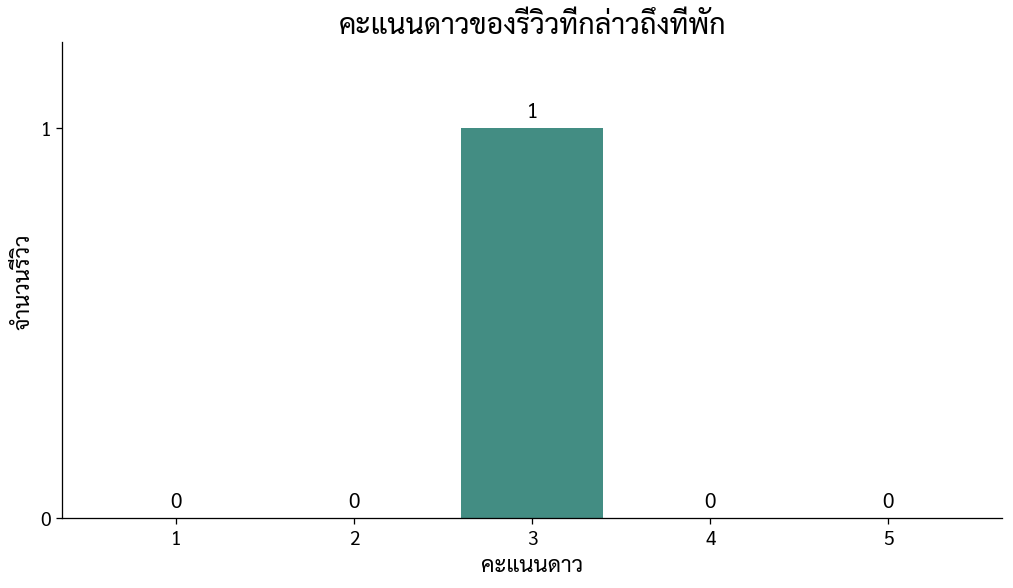

ประเด็น ที่พัก: 1 รีวิว คิดเป็น 0.3% ของรีวิวทั้งหมด
คะแนนดาวเฉลี่ยของรีวิวกลุ่มนี้ = 3.00 จาก 5 ดาว
มีรีวิวพร้อมป้ายน้อยกว่า 10 รายการ จึงไม่รายงานความสัมพันธ์ภายในประเด็น
การกล่าวถึงประเด็นไม่ได้แปลว่าชมหรือตำหนิประเด็นนั้น ต้องอ่านข้อความประกอบ


In [ ]:
plot_one_topic('ที่พัก', 35)


## หากเปลี่ยนไฟล์แล้วมีประเด็นใหม่
กรอกชื่อแท็กและเลขภาพด้านล่างเพื่อสร้างกราฟเพิ่มครั้งละหนึ่งประเด็น ปล่อยว่างไว้หากใช้ไฟล์เดิม

In [ ]:
EXTRA_TOPIC = ""
if EXTRA_TOPIC:
    plot_one_topic(EXTRA_TOPIC, 36)


## บันทึกผลและดาวน์โหลด
รวมกราฟแต่ละภาพไว้ใน ZIP พร้อมตารางเดิมและแบบฟอร์มตรวจป้าย

In [ ]:
for name in model_names[:2]:
    data[f'{name}_star_band_mismatch'] = data[f'{name}_prediction'].to_numpy() != star_band
# เป็นแค่ผู้สมัครให้ตรวจ: อาจเป็นโมเดลผิด ข้อความผสม หรือดาวกับข้อความไม่ตรงกันจริง
mismatch = data[[f'{n}_star_band_mismatch' for n in model_names[:2]]].any(axis=1)
export_cols = ['row_id','platform','stars','text','label','date_ce','topics_raw','fold'] + [
    c for c in data.columns if any(c.startswith(n+'_') for n in model_names[:2])]
save_table(data[export_cols], 'review_predictions')
save_table(data.loc[mismatch,export_cols], 'mismatch_candidates_for_manual_review')
audit['mismatch_candidates_either_model'] = int(mismatch.sum())
audit['independent_label_verification_declared'] = LABELS_INDEPENDENTLY_VERIFIED
audit['input_sha256'] = hashlib.sha256(Path(INPUT_FILE).read_bytes()).hexdigest()
audit['versions'] = {p: importlib.metadata.version(p) for p in ['pandas','numpy','scikit-learn','scipy','matplotlib','openpyxl']}
(OUT/'run_metadata.json').write_text(json.dumps(audit,ensure_ascii=False,indent=2),encoding='utf-8')
readme = f'''ผลวิเคราะห์รีวิวสวนสัตว์สงขลา
จำนวนรีวิวที่ผ่านเงื่อนไข {len(df)} แถว ใช้โมเดล {len(data)} แถว
แหล่งป้าย: {label_source}
ป้ายตรงกลุ่มดาว {agreement:.1%} การตรงกันสูงเป็นเหตุให้ตรวจวิธีติดป้าย ไม่ใช่ข้อพิสูจน์ว่าป้ายมาจากดาว

วิธี: TF-IDF character n-grams 3–5, max_features=30000, min_df=1, sublinear_tf=True
MultinomialNB alpha=1 พร้อม sample_weight balanced ในชุดฝึกแต่ละ fold
LogisticRegression C=1, max_iter=3000, class_weight=balanced
StratifiedGroupKFold {n_splits} folds, seed={SEED}; ข้อความซ้ำอยู่ fold เดียวกัน
TF-IDF เรียนรู้เฉพาะชุดฝึกแต่ละ fold ไม่ใช้ดาวเป็น feature ไม่ใช้ป้ายที่แปลงจากดาว
คะแนนต่อเนื่อง = P(positive) - P(negative) จากการทำนาย out of fold
ใช้คะแนนเป็นดัชนีโมเดล ไม่ใช่ความน่าจะเป็นที่ปรับเทียบแล้ว

ข้อจำกัดที่ต้องใช้ประกอบผล
1. หากป้ายต้นทางได้จากดาว ความสัมพันธ์ยังปนความเป็นวงกลม แม้ใช้ OOF แล้ว
2. Majority baseline ใช้ตรวจว่าประสิทธิภาพดูดีเพียงเพราะป้ายบวกมากหรือไม่ ให้ดู Macro-F1 และ recall รายคลาส
3. รายงาน Pearson และ Spearman เชิงพรรณนา ไม่ได้คำนวณ p-value/CI เพราะ OOF ใช้ชุดฝึกร่วมกัน
4. ประเด็นมาจากแท็ก Excel ไม่ใช่โมเดลตรวจประเด็น และ sentiment เป็นระดับรีวิวทั้งข้อความ
5. ค่าเฉลี่ยดาวของรีวิวที่กล่าวถึงเรื่องหนึ่ง ไม่ใช่คะแนนความพึงพอใจเฉพาะเรื่องนั้น
6. topic_correlations เป็นการสำรวจหลายประเด็น ไม่มีการทดสอบนัยสำคัญหรือสรุปเหตุและผล
7. ข้อความซ้ำอาจเป็นคนละคน จึงไม่ลบอัตโนมัติ ยังต้องตรวจข้อความเกือบซ้ำ/ผู้รีวิวซ้ำ/การแปล
8. Excel ไม่ได้ยืนยัน URL ต้นฉบับแต่ละรีวิว ควรเติม URL วันที่เก็บ และ original_language/translated
9. ภาษาไทยที่ตรวจพบยืนยันได้เพียงข้อความในไฟล์เป็นภาษาไทย ไม่ยืนยันว่ารีวิวต้นฉบับเป็นไทย
10. ข้อมูลต่างแพลตฟอร์มและช่วงเวลาอาจมีอคติ ผลนี้ใช้กับตัวอย่างที่เก็บมา ไม่ใช่นักท่องเที่ยวทั้งหมด

ไฟล์สำคัญ
correlations.csv ค่า r/rho ภาพรวมและรายแพลตฟอร์ม
model_comparison.csv และ report_*.csv ประสิทธิภาพรวมและรายคลาส
topic_summary.csv จำนวน ร้อยละรีวิว และดาวเฉลี่ย พร้อมชื่อประเด็นไทย/อังกฤษ
topic_correlations.csv การกล่าวถึงประเด็นเทียบดาว และความสัมพันธ์ภายในประเด็น n>=10
review_predictions.csv ผลทำนายแต่ละแถวแบบ out of fold
mismatch_candidates_for_manual_review.csv รายการให้ตรวจ ไม่ใช่รายการที่ผิดแน่นอน
blind_annotation_template.csv ข้อความแบบซ่อนดาวและซ่อนป้ายเดิม

การติดป้ายใหม่
ผู้ประเมิน 2 คนอ่านเฉพาะข้อความ กำหนด positive/neutral/negative โดยไม่เห็นดาว
ให้กำหนดวิธีจัดข้อความผสมไว้ล่วงหน้า แยกข้อความกำกวมหรือไม่เข้าใจไว้ตรวจ
บันทึก annotator_1/annotator_2 ใช้ Cohen kappa ตรวจความสอดคล้องก่อนตกลงป้าย
กรอกป้ายที่ตกลงแล้วใน sentiment_verified คง row_id และ text_hash ไว้
อัปโหลด CSV และตั้ง ANNOTATION_FILE เป็น path นั้น รันใหม่ตั้งแต่ต้น
โค้ดจะใช้เฉพาะแถวที่มีป้ายที่ตรวจแล้ว ไม่ผสมกับป้ายเดิมโดยเงียบ ๆ
การใส่ LABELS_INDEPENDENTLY_VERIFIED=True เป็นเพียงบันทึกการยืนยันของผู้วิจัย ไม่ใช่การตรวจอัตโนมัติ
'''
(OUT/'README_TH.txt').write_text(readme,encoding='utf-8')
# บันทึกคู่มือกราฟภาษาไทยและสิทธิ์ใช้งานฟอนต์
(OUT / "GRAPH_GUIDE_TH.txt").write_text("กราฟหลัก 01–12 แสดงทีละคำถามและทีละโมเดล\nกราฟ 13–35 แสดงประเด็นทีละเรื่อง\nทุกภาพใช้ภาษาไทยและฟอนต์ Sarabun\nดาวของกลุ่มรีวิวไม่ใช่คะแนนความพึงพอใจเฉพาะประเด็น\n", encoding="utf-8")
(OUT / "FONT_LICENSE.txt").write_text(FONT_LICENSE, encoding="utf-8")
import zipfile
ZIP_PATH = str(OUT) + '.zip'
with zipfile.ZipFile(ZIP_PATH, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for result_file in sorted(OUT.iterdir()):
        if result_file.is_file():
            archive.write(result_file, arcname=result_file.name)
with zipfile.ZipFile(ZIP_PATH) as archive:
    if archive.testzip() is not None:
        raise RuntimeError('ไฟล์ ZIP ไม่สมบูรณ์ กรุณารันเซลล์บันทึกผลอีกครั้ง')
print('\nบันทึกผลครบแล้ว:', OUT)
print('ไฟล์รวมกราฟและตาราง:', ZIP_PATH)




บันทึกผลครบแล้ว: zoo_results/20260917_102248_361452
ไฟล์รวมกราฟและตาราง: zoo_results/20260917_102248_361452.zip


In [ ]:
if IN_COLAB:
    colab_files.download(ZIP_PATH)


## ผลตัวอย่างจากการทดสอบไฟล์ที่แนบ

ค่าด้านล่างเป็นผลจากการทดสอบในสภาพแวดล้อม Python ของผู้จัดทำ ไม่ใช่ค่าที่อัปเดตอัตโนมัติเมื่อเปลี่ยน Excel ให้ใช้ตารางที่แสดงจากการรันด้านบนเป็นผลของไฟล์ปัจจุบัน

| โมเดล | Accuracy | Macro-F1 | Pearson r | Spearman rho |
|---|---:|---:|---:|---:|
| Naïve Bayes | 0.590 | 0.477 | 0.559 | 0.426 |
| Logistic Regression | 0.850 | 0.481 | 0.609 | 0.485 |
| Majority baseline | 0.823 | 0.301 | ไม่ใช้ | ไม่ใช้ |

ความสัมพันธ์เป็นบวกในตัวอย่างนี้ แต่ Macro-F1 ยังต่ำ และความเป็นอิสระของป้ายยังต้องตรวจ Logistic Regression จำแนก neutral ถูกเพียง 1 จาก 27 รีวิว จึงไม่ควรสรุปจาก Accuracy เพียงตัวเดียว

แท็กประเด็นหลัก: สัตว์ 211 รีวิว ครอบครัว 117 รีวิว ความประทับใจ 82 รีวิว การแสดง 74 รีวิว


# รายการ Literature Review สำหรับโครงงานสวนสัตว์สงขลา

โครงงานตาม proposal คือ **การวิเคราะห์ความสัมพันธ์ระหว่างคะแนนดาวและเนื้อหารีวิวของนักท่องเที่ยวสวนสัตว์สงขลาด้วย Machine Learning** ใช้รีวิวภาษาไทยจาก Google Maps และ TripAdvisor เปรียบเทียบ Naïve Bayes กับ Logistic Regression เพื่อจำแนกความรู้สึก 3 กลุ่ม และใช้ Pearson correlation เชื่อมคะแนนความรู้สึกกับดาว

เอกสารนี้เป็นรายการหัวข้อและแหล่งอ่านที่เกี่ยวข้อง พร้อมวิธีเชื่อมกับงาน ไม่ใช่การทบทวนวรรณกรรมอย่างเป็นระบบหรือการยืนยันว่าไม่มีใครทำงานลักษณะนี้มาก่อน ตรวจแหล่งออนไลน์วันที่ 17 กันยายน 2026

## 1 หัวข้อที่ควรมีในบททบทวนวรรณกรรม

| ลำดับ | หัวข้อ | ประเด็นที่ต้องอธิบาย | เชื่อมกับวัตถุประสงค์ |
|---|---|---|---|
| 1 | รีวิวออนไลน์และความพึงพอใจของนักท่องเที่ยว | ข้อความกับดาวให้ข้อมูลต่างกัน ตัวอย่างจากธุรกิจท่องเที่ยวและบริการ | 8.1 และ 8.3 |
| 2 | การเก็บและคัดเลือกข้อมูลรีวิว | หน่วยวิเคราะห์คือหนึ่งรีวิว เงื่อนไขภาษาไทย มีข้อความพร้อมดาว แหล่งที่มาและช่วงเวลา | 8.1 |
| 3 | Sentiment Analysis | ความหมายของ positive neutral negative และการประเมินข้อความผสม | 8.2 |
| 4 | การประมวลผลข้อความภาษาไทย | การตัดคำ อักขระแฝง คำปฏิเสธ ภาษาพูด emoji และข้อความแปล | 8.2 |
| 5 | การแปลงข้อความเป็นตัวเลข | Bag of Words TF-IDF word n-grams และ character n-grams | 8.2 |
| 6 | Multinomial Naïve Bayes | สมมติฐานความเป็นอิสระ คุณลักษณะไม่ติดลบ smoothing และข้อจำกัด | 8.2 |
| 7 | Logistic Regression สำหรับข้อความ | การจำแนกหลายคลาส regularization และการถ่วงน้ำหนักคลาส | 8.2 |
| 8 | การวิเคราะห์ประเด็นในรีวิว | หนึ่งรีวิวมีหลายประเด็น แยก topic extraction กับ aspect sentiment | 8.2 และ 8.3 |
| 9 | ความสัมพันธ์ระหว่างดาวกับข้อความ | Pearson r การกำหนดคะแนนความรู้สึก และ Spearman สำหรับตรวจเพิ่มเติม | 8.3 |
| 10 | การประเมินโมเดลและความน่าเชื่อถือของป้าย | Macro-F1 precision recall confusion matrix baseline cross-validation และ data leakage | 8.2 และ 8.3 |

## 2 งานวิจัยที่ควรอ่านและวิธีนำมาใช้

### 1 Pang Lee และ Vaithyanathan 2002

**Thumbs up? Sentiment Classification using Machine Learning Techniques**. Proceedings of EMNLP 2002, 79–86. DOI 10.3115/1118693.1118704. [บทความและไฟล์ต้นฉบับ](https://aclanthology.org/W02-1011/)

งานพื้นฐานเรื่องการจำแนกความรู้สึกของรีวิวด้วย Machine Learning เหมาะใช้ปูพื้นว่าการวิเคราะห์ความคิดเห็นต่างจากการจำแนกหัวข้ออย่างไร และเชื่อมไปสู่เหตุผลที่ใช้ Naïve Bayes เป็นตัวเปรียบเทียบในโครงงานนี้

สิ่งที่ควรบันทึกเมื่ออ่าน: ชนิดข้อมูล คุณลักษณะ วิธีแบ่งชุดข้อมูล อัลกอริทึมที่เปรียบเทียบ และวิธีประเมิน ไม่ควรนำผลจากรีวิวภาษาอังกฤษมาอ้างว่าโมเดลจะได้ผลเท่ากันกับรีวิวสวนสัตว์ภาษาไทย

### 2 Pang และ Lee 2005

**Seeing Stars: Exploiting Class Relationships for Sentiment Categorization with Respect to Rating Scales**. Proceedings of ACL 2005, 115–124. [บทความและไฟล์ต้นฉบับ](https://aclanthology.org/P05-1015/)

เกี่ยวข้องกับการจำแนกความรู้สึกที่มีลำดับระดับตามสเกลคะแนน ใช้ประกอบการอธิบายว่าความรู้สึกมีมากกว่าสองขั้ว และระดับคะแนนมีความสัมพันธ์ระหว่างกลุ่ม

การนำมาใช้กับโครงงาน: นิยามกลุ่มบวก กลาง ลบ และอธิบายความต่างระหว่างการทำนายดาวกับการวัดความสัมพันธ์ของดาวกับความรู้สึก งานนี้ต้องระวังไม่ใช้ดาวสร้างป้ายแล้วนำผลกลับมาพิสูจน์ความสอดคล้องกับดาว

### 3 Wang และ Manning 2012

**Baselines and Bigrams: Simple, Good Sentiment and Topic Classification**. Proceedings of ACL 2012 Volume 2, 90–94. [บทความและไฟล์ต้นฉบับ](https://aclanthology.org/P12-2018/)

ใช้ทบทวนบทบาทของโมเดลพื้นฐานและคุณลักษณะ n-grams ในการจำแนกความรู้สึกและหัวข้อ โครงงานควรมี baseline และให้ทั้งสองโมเดลใช้คุณลักษณะกับชุดแบ่งข้อมูลเดียวกันเพื่อเปรียบเทียบอย่างเป็นธรรม

Notebook ที่แนบเป็น baseline ของโครงงาน ใช้ TF-IDF ระดับตัวอักษร 3–5 ตัว ไม่ได้ทำซ้ำการทดลองหรือใช้โมเดล NB-SVM ตามบทความนี้ การตัดสินใจใช้ character n-grams เป็นทางเลือกในการออกแบบของโครงงาน ไม่ใช่ข้ออ้างว่าบทความยืนยันวิธีนี้สำหรับภาษาไทย

### 4 Maks และ Vossen 2013

**Sentiment Analysis of Reviews: Should we analyze writer intentions or reader perceptions?** Proceedings of RANLP 2013, 415–419. [บทความและไฟล์ต้นฉบับ](https://aclanthology.org/R13-1054/)

เกี่ยวข้องโดยตรงกับปัญหาที่คะแนนดาวซึ่งผู้เขียนให้ อาจไม่ตรงกับความรู้สึกที่ผู้อ่านตีความจากข้อความ ใช้เป็นกรอบอภิปรายความหมายของป้ายจริงและความไม่ตรงกันระหว่างดาวกับรีวิว

สำหรับโครงงานนี้ควรให้ผู้ประเมินอ่านข้อความโดยไม่เห็นดาว กำหนดกติกาข้อความผสมไว้ก่อน และใช้กรณีดาวกับผลทำนายไม่ตรงกันเป็นรายการให้คนตรวจ ไม่ควรเรียกว่าโมเดลพบการให้ดาวผิดแน่นอน

### 5 Pontiki และคณะ 2014

**SemEval-2014 Task 4: Aspect Based Sentiment Analysis**. Proceedings of SemEval 2014, 27–35. DOI 10.3115/v1/S14-2004. ผู้เขียน: Maria Pontiki, Dimitris Galanis, John Pavlopoulos, Harris Papageorgiou, Ion Androutsopoulos และ Suresh Manandhar. [บทความและไฟล์ต้นฉบับ](https://aclanthology.org/S14-2004/)

เป็นแหล่งหลักสำหรับแยก “ประเด็นที่กล่าวถึง” ออกจาก “ความรู้สึกต่อประเด็นนั้น” เช่น ข้อความหนึ่งอาจชมบรรยากาศแต่ตำหนิราคา จึงไม่สามารถนำป้ายบวกของทั้งรีวิวไปแทนความรู้สึกบวกต่อทุกประเด็นได้

ใน Excel มีแท็กประเด็นอยู่แล้ว โค้ดจึงสรุปแท็กเหล่านั้นและความรู้สึกระดับรีวิว หากต้องการอ้างว่าระบบวิเคราะห์ความรู้สึกเฉพาะด้าน ต้องเพิ่มป้ายระดับประเด็นหรือประโยคและประเมินโมเดลส่วนนั้นแยกต่างหาก

### 6 Xiang Schwartz Gerdes และ Uysal 2015

**What can big data and text analytics tell us about hotel guest experience and satisfaction?** International Journal of Hospitality Management, 44, 120–130. DOI 10.1016/j.ijhm.2014.10.013. ผู้เขียน: Zheng Xiang, Zvi Schwartz, John H. Gerdes Jr. และ Muzaffer Uysal. [ระเบียนบทความจากสำนักพิมพ์](https://www.sciencedirect.com/science/article/abs/pii/S0278431914001698)

เกี่ยวข้องเชิงบริบทกับการใช้ข้อความรีวิวเพื่อศึกษาประสบการณ์และความพึงพอใจในธุรกิจบริการและท่องเที่ยว ใช้ช่วยวางเหตุผลว่าการอ่านข้อความเพิ่มรายละเอียดจากคะแนนรวมได้อย่างไร

ในการนำมาใช้ ควรเปรียบเทียบว่าประสบการณ์โรงแรมต่างจากสวนสัตว์อย่างไร เช่น สัตว์ การแสดง ครอบครัว และสวัสดิภาพสัตว์เป็นประเด็นเฉพาะของงานนี้ รายการนี้ตรวจสอบข้อมูลบรรณานุกรมและคำอธิบายแหล่งตีพิมพ์ได้ แต่ไม่ได้อ่านฉบับเต็ม จึงไม่รายงานตัวเลขผลทดลองหรือวิธีละเอียดที่ยังไม่ได้ตรวจสอบ

### 7 Phatthiyaphaibun และคณะ 2023

**PyThaiNLP: Thai Natural Language Processing in Python**. Proceedings of NLP-OSS 2023, 25–36. DOI 10.18653/v1/2023.nlposs-1.4. ผู้เขียน: Wannaphong Phatthiyaphaibun, Korakot Chaovavanich, Charin Polpanumas, Arthit Suriyawongkul, Lalita Lowphansirikul, Pattarawat Chormai, Peerat Limkonchotiwat, Thanathip Suntorntip และ Can Udomcharoenchaikit. [บทความและไฟล์ต้นฉบับ](https://aclanthology.org/2023.nlposs-1.4/)

แนะนำเครื่องมือประมวลผลภาษาไทย ชุดข้อมูล และโมเดล ใช้เป็นแหล่งทบทวนส่วนเตรียมข้อความภาษาไทย และเป็นทางเลือกสำหรับการทดลองเพิ่ม word-level TF-IDF ภายหลัง

โค้ดเวอร์ชันที่ให้มารันด้วย character n-grams จึงไม่ได้ติดตั้งหรือเรียก PyThaiNLP อย่าเขียนในรายงานว่าใช้ PyThaiNLP หากยังไม่ได้เปลี่ยนโค้ดและรันทดลองจริง

## 3 แหล่งข้อมูลและเอกสารวิธีการเพิ่มเติม

แยกแหล่งเหล่านี้จากรายการงานวิจัย เพราะเป็นชุดข้อมูล ตำรา หรือคู่มือซอฟต์แวร์

| แหล่ง | ใช้ทบทวนอะไร | การใช้ในโค้ดนี้ |
|---|---|---|
| [Wisesight Sentiment Corpus](https://github.com/PyThaiNLP/wisesight-sentiment) | ตัวอย่างชุดข้อมูลความคิดเห็นภาษาไทยและป้ายกำกับ | อ่านประกอบ ไม่ได้นำมารวมฝึก และไม่ควรถือว่าข้อมูลโซเชียลแทนข้อมูลสวนสัตว์ได้ทันที |
| [Introduction to Information Retrieval เรื่อง TF-IDF](https://nlp.stanford.edu/IR-book/html/htmledition/tf-idf-weighting-1.html) | แนวคิดการถ่วงน้ำหนักคุณลักษณะข้อความ | ใช้ TF-IDF ในชุดฝึกแต่ละ fold |
| [scikit-learn เรื่อง Logistic Regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression) | การจำแนกข้อความและ regularization | ใช้ LogisticRegression กับ class_weight balanced |
| [scikit-learn เรื่อง StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html) | การแบ่งข้อมูลรักษากลุ่มไม่ให้ข้ามชุด | จัดข้อความซ้ำใน fold เดียวกัน |
| [SciPy เรื่อง Pearson correlation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) | ความหมายและข้อสมมติของ Pearson r | รายงาน r เชิงพรรณนาและเสริม Spearman |

## 4 กรอบวิเคราะห์ที่สอดคล้องกับวัตถุประสงค์

| วัตถุประสงค์ | ข้อมูลที่ใช้ | วิธี | ผลลัพธ์และกราฟ |
|---|---|---|---|
| 8.1 รวบรวมรีวิวจริง | แพลตฟอร์ม ดาว ข้อความ วันที่ | ตรวจความครบถ้วน ภาษา ดาวผิดช่วง และข้อความซ้ำ | จำนวนรีวิวต่อแหล่ง การกระจายดาว และรายการคุณภาพข้อมูล |
| 8.2 ความรู้สึก | ข้อความเป็น X ป้ายที่ประเมินจากข้อความเป็น y | TF-IDF พร้อม Naïve Bayes และ Logistic Regression | สัดส่วนความรู้สึก Macro-F1 recall และ confusion matrix |
| 8.2 ประเด็นหลัก | แท็กประเด็นที่มีใน Excel | แยกแท็กหลายประเด็นแล้วนับรีวิว | ประเด็นยอดนิยมและสัดส่วนรีวิวที่กล่าวถึง |
| 8.3 ดาวกับความรู้สึก | ดาว 1–5 และคะแนนโมเดลจาก OOF | Pearson และ Spearman | Scatter plot และ heatmap ดาวกับคลาสที่ทำนาย |
| 8.3 ดาวกับประเด็น | การกล่าวถึงประเด็นและคะแนนดาว | ดาวเฉลี่ย และ Pearson ของการกล่าวถึงแบบ 0/1 กับดาว | กราฟดาวเฉลี่ยรายประเด็น ตารางความสัมพันธ์ |
| 8.3 ความสอดคล้องภายในประเด็น | รีวิวที่กล่าวถึงแต่ละประเด็น | Pearson ดาวกับคะแนน OOF ภายในกลุ่ม n ตั้งแต่ 10 | ตารางแยกประเด็น ไม่อ้างว่าความรู้สึกเป็นระดับประเด็น |

สูตรคะแนนความรู้สึกของโค้ดคือ **s = P(positive) − P(negative)** มีช่วง −1 ถึง 1 คะแนนบวกมากหมายถึงโมเดลเอนมาทางบวก คะแนนนี้ใช้เป็นดัชนี ไม่ได้ผ่านการปรับเทียบความน่าจะเป็น และไม่ใช่คะแนนความพึงพอใจจริงของบุคคล

OOF หมายถึงทำนายแต่ละรีวิวด้วยโมเดลที่ฝึกจาก fold อื่น ทั้ง TF-IDF และโมเดลเรียนรู้เฉพาะข้อมูลฝึก ไม่มีการใส่ดาวเป็น feature แต่ OOF แก้ปัญหาป้ายที่ได้มาจากดาวไม่ได้ จึงยังต้องตรวจวิธีให้ป้าย

## 5 ผลตรวจไฟล์และผลทดลองเบื้องต้น

แหล่งข้อมูลส่วนนี้คือ proposal(1).docx หัวข้อ 7–8 และ 250comment.xlsx Sheet1 ไม่ใช่แหล่งจากอินเทอร์เน็ต ชื่อไฟล์ระบุ 250 แต่มีข้อมูลจริง 300 รีวิว ทั้งหมดมีข้อความภาษาไทยและคะแนนดาวที่ใช้ได้ Google Maps 253 รีวิว และ TripAdvisor 47 รีวิว การตรวจนี้ยังไม่ได้ยืนยันว่าทุกข้อความคัดมาจากต้นฉบับจริงหรือเป็นภาษาไทยตั้งแต่ต้น

ป้ายเดิมเป็นบวก 247 กลาง 27 ลบ 26 และตรงกับกลุ่มดาว 1–2=ลบ 3=กลาง 4–5=บวก จำนวน 295/300 หรือ 98.3% ข้อสังเกตนี้ไม่พิสูจน์ว่าป้ายสร้างจากดาว แต่ควรตรวจที่มาของป้ายก่อนนำไปสรุปว่าดาวสอดคล้องกับความรู้สึกที่วัดอย่างอิสระ

ข้อความซ้ำหลังปรับรูปแบบ 1 แถวส่วนเกิน เป็นข้อความสั้น “เด็กๆชอบ” โค้ดคงทั้งสองรีวิวไว้และจัดอยู่ fold เดียวกัน การคงข้อความซ้ำไม่ได้ยืนยันว่าเป็นคนละรีวิว ต้องตรวจต้นฉบับเพิ่มเติม

ผลจากการรันจริงกับไฟล์ที่แนบ ใช้ 5 folds และ seed 42:

| โมเดล | Accuracy | Macro-F1 | Balanced accuracy | Pearson r กับดาว | Spearman rho |
|---|---:|---:|---:|---:|---:|
| Multinomial Naïve Bayes | 0.590 | 0.477 | 0.599 | 0.559 | 0.426 |
| Logistic Regression | 0.850 | 0.481 | 0.447 | 0.609 | 0.485 |
| ทำนายคลาสส่วนใหญ่เสมอ | 0.823 | 0.301 | 0.333 | ไม่ใช้ | ไม่ใช้ |

**อ่านผลอย่างไร:** ทั้งสองโมเดลให้คะแนนข้อความที่มีความสัมพันธ์ทางบวกกับดาวในชุดตัวอย่าง แต่ยังใช้ป้ายเบื้องต้น Logistic Regression มี Accuracy สูงกว่า ขณะที่ Macro-F1 ของทั้งคู่ยังใกล้ 0.48 และ Logistic Regression จำแนก neutral ถูกเพียง 1 จาก 27 รีวิว จึงยังไม่เหมาะที่จะสรุปว่าจำแนกความรู้สึกได้ดีครบทุกกลุ่ม หรือใช้สัดส่วนผลทำนายแทนความรู้สึกจริงทั้งหมด

ประเด็นที่ถูกกล่าวถึงมากสุดตามแท็กเดิมคือ สัตว์ 211 รีวิว ครอบครัว 117 รีวิว ความประทับใจ 82 รีวิว และการแสดง 74 รีวิว หนึ่งรีวิวมีหลายแท็กจึงรวมร้อยละเกิน 100 ได้ “สัตว์” กับ “จำนวนสัตว์” เป็นคนละแท็กตามไฟล์ ควรเขียนคำจำกัดความให้ชัดก่อนสรุปผล

## 6 สิ่งที่ต้องทำก่อนเขียนข้อสรุปวิจัย

1. ยืนยันที่มาของแต่ละรีวิว เพิ่ม URL วันที่เก็บ ภาษาเดิมและสถานะการแปล อย่าอนุมานสัญชาติหรือภาษาเดิมจากที่อยู่โปรไฟล์
2. กำหนดกติกาป้ายโดยไม่อิงดาว ให้ผู้ประเมินสองคนอ่านข้อความแบบซ่อนดาวและป้ายเดิม นิยามข้อความผสมและข้อความกำกวมให้ตรงกัน
3. บันทึกป้ายแยกคน วัดความสอดคล้องด้วย Cohen kappa ก่อนตกลงป้ายสุดท้าย แล้วรันใหม่ด้วย sentiment_verified
4. รายงานผลรายคลาสและ baseline คู่กับ Accuracy ไม่เลือกรายงานเฉพาะโมเดลที่ได้ correlation สูงกว่า
5. หากจะปรับ C alpha หรือเลือกคุณลักษณะจากผลทดสอบ ต้องใช้ inner validation/nested CV หรือเก็บชุดทดสอบใหม่ ไม่ใช้ OOF ชุดเดิมปรับซ้ำแล้วอ้างว่าเป็นการประเมินอิสระ
6. กราฟความรู้สึกแยกประเด็นในโค้ดหมายถึงความรู้สึกของรีวิวที่กล่าวถึงประเด็น ไม่ใช่ความรู้สึกเฉพาะประเด็นนั้น หากต้องการอย่างหลังต้องเพิ่มข้อมูลและโมเดล

จุดที่อาจใช้วางช่องว่างงานวิจัยคือการประยุกต์กับรีวิวภาษาไทยของสวนสัตว์สงขลา การเปรียบเทียบโมเดลบนชุดข้อมูลเดียวกัน และการตรวจดาวกับป้ายความรู้สึกที่ประเมินอย่างอิสระ นี่เป็นกรอบเสนอสำหรับโครงงาน ยังไม่ใช่ข้อยืนยันความใหม่จากการค้นวรรณกรรมครบถ้วน


## ที่มาฟอนต์ไทย

ใช้ Sarabun Regular จาก [Google Fonts](https://github.com/google/fonts/tree/main/ofl/sarabun) ภายใต้ SIL Open Font License 1.1 เก็บข้อความใบอนุญาตไว้ในตัวแปร FONT_LICENSE และส่งออกพร้อมผลวิเคราะห์ ฟอนต์ถูกฝังใน Notebook เพื่อให้รันได้โดยไม่ต้องเชื่อมต่อแหล่งดาวน์โหลดฟอนต์
